# **AI METHODS I: Group 5**
----
## Day1: Data cleaning and Exploratory Data Analysis (EDA)

### Goals

1. Load the dataset ""melbourne_house_prices.csv"" from Kaggle or upload csv using **pandas**.

    Steps:    
    a. Choose a python environment    
    b. Set up / Install packages with **.pip** and **import as**                
    c. Set up folders with realitve paths so they can work in any computer     
    d. Import CSV file with **.read()**      
          
2. Inspect the dataset and write a short **dataset card** (source, content, limitations).        

    Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing |   
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 
      
3. Detect and fix the classic **data problems**:       
           
    Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers.           


4. **Feature Engineering** 
     
    Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready   

5. **Comparing** raw and clean data sets

6. **(EDA)** Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

    Steps:      
    a.  **Univariate**: one variable at a time    
    b.  **Bivariate**: two variables together       
    c. **Multivariate**: several variables at once      

7. Save a clean, **model-ready dataset** 

### 1.a. Choose a python environment

In [60]:
# Choose python environment. If doesn't work use this in the terminal--->>   
# (1) python -m venv .venv 
# (2) .venv\Scripts\Activate.ps1

### 1.b. Set up / Install packages with **.pip** and **import as**

In [61]:
# Set-up/ install packages.
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [62]:
# Import installed packages/ libraries into environment?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

### 1.c. Files Set-Up for the Project
 
1. Set up folders with realitve paths so they can work in any computer. 
2. Set-up display options.
3. Save images as png in respective folders.

In [63]:
# Set-up folders --- data and figures --- relative paths to enable the notebook to work on any computer.

DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here

DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

In [64]:
# pandas display options 
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# plot style 
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42

In [65]:
# "save_fig()" exports plots as .png 
# Creating a function to call when we need to save a figure (plot during analysis) onto the computer.

def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

### 1.d. Import CSV file with **.read()**

In [66]:
# Import csv file from data folder.
df = pd.read_csv(
    DATA_DIR / "melbourne_house_prices.csv"
)

# print info of imported csv data --- check
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 34,857 rows and 21 columns


# 2. Inspect the dataset

Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing    
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 

### Dataset card

| | |
|---|---|
| **Name** | Melbourne House Prices |
| **Source** | Kaggle, [Chaitanya Jamble](https://www.kaggle.com/datasets/anthonypino/melbourne-housing-market) |
| **Origin** |This data was scraped from publicly available results posted every week from Domain.com.au. A dataset for Melbourne's Housing Market. |
| **Unit of observation** | NEED TO FILL |
| **Size (raw)** | 34,857 Rows by 21 Columns |
| **Target for Day 2** | NEED TO FILL |
| **Licence** | Check the *License* field on the Kaggle page before re-using the data in a publication |
| **Known limitations** | NEED TO FILL |

### 2.a. **.shape** | Number of rows and columns  

In [67]:
# Use shape to see number of rows and columns
df.shape

(34857, 21)

### 2.b. **.head()** | The first rows: what the values look like    

In [68]:
# The first 5 rows.
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.50,"3,067.00",2.00,1.00,1.00,126.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
1,Abbotsford,85 Turner St,2,h,"1,480,000.00",S,Biggin,3/12/2016,2.50,"3,067.00",2.00,1.00,1.00,202.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,4/02/2016,2.50,"3,067.00",2.00,1.00,0.00,156.00,79.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.50,"3,067.00",3.00,2.00,1.00,0.00,NaN,NaN,Yarra City Council,-37.81,145.01,Northern Metropolitan,"4,019.00"
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,4/03/2017,2.50,"3,067.00",3.00,2.00,0.00,134.00,150.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"


### 2.c. **.info()** | Column names, data types and how many values are *not* missing

In [69]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  object 
 1   Address        34857 non-null  object 
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  object 
 4   Price          27247 non-null  float64
 5   Method         34857 non-null  object 
 6   SellerG        34857 non-null  object 
 7   Date           34857 non-null  object 
 8   Distance       34856 non-null  float64
 9   Postcode       34856 non-null  float64
 10  Bedroom2       26640 non-null  float64
 11  Bathroom       26631 non-null  float64
 12  Car            26129 non-null  float64
 13  Landsize       23047 non-null  float64
 14  BuildingArea   13742 non-null  float64
 15  YearBuilt      15551 non-null  float64
 16  CouncilArea    34854 non-null  object 
 17  Lattitude      26881 non-null  float64
 18  Longti

### 2.d. **.describe()** | Summary statistics (mean, min, max, quartiles…)

In [70]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Suburb,34857,351,Reservoir,844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,34857,34009,5 Charles St,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,"34,857.00",NaN,NaN,NaN,3.03,0.97,1.00,2.00,3.00,4.00,16.00
Type,34857,3,h,23980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"27,247.00",NaN,NaN,NaN,"1,050,173.34","641,467.13","85,000.00","635,000.00","870,000.00","1,295,000.00","11,200,000.00"
Method,34857,9,S,19744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,34857,388,Jellis,3359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,34857,78,28/10/2017,1119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance,"34,856.00",NaN,NaN,NaN,11.18,6.79,0.00,6.40,10.30,14.00,48.10
Postcode,"34,856.00",NaN,NaN,NaN,"3,116.06",109.02,"3,000.00","3,051.00","3,103.00","3,156.00","3,978.00"


# 3. Detect and fix the classic data problems
           
Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers. 

### 3.a. Make a copy of de dataframe with **.copy()**

In [71]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

### 3.b. Tidy columns names if it's necessary 

In [72]:
# # Give new names to columns if they are not proper.

# new_names = {"Old_Name":"new_name",
#              "Old_Name_2":"new_name_2"}
# df_clean = df_clean.rename(columns=new_names)
# df_clean.columns.tolist()

# # Not required for this Data Set.

### 3.c. Remove all duplicated values with **.duplicated()**       


In [73]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")

Number of duplicate rows: 1


### 4.d. Get an overview of **missing values()**  
   

In [74]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_missing,pct_missing
BuildingArea,21115,60.58
YearBuilt,19306,55.39
Landsize,11810,33.88
Car,8728,25.04
Bathroom,8226,23.60
Bedroom2,8217,23.57
Longtitude,7976,22.88
Lattitude,7976,22.88
Price,7610,21.83
Regionname,3,0.01


Figure saved to figures\01_missing_values.png


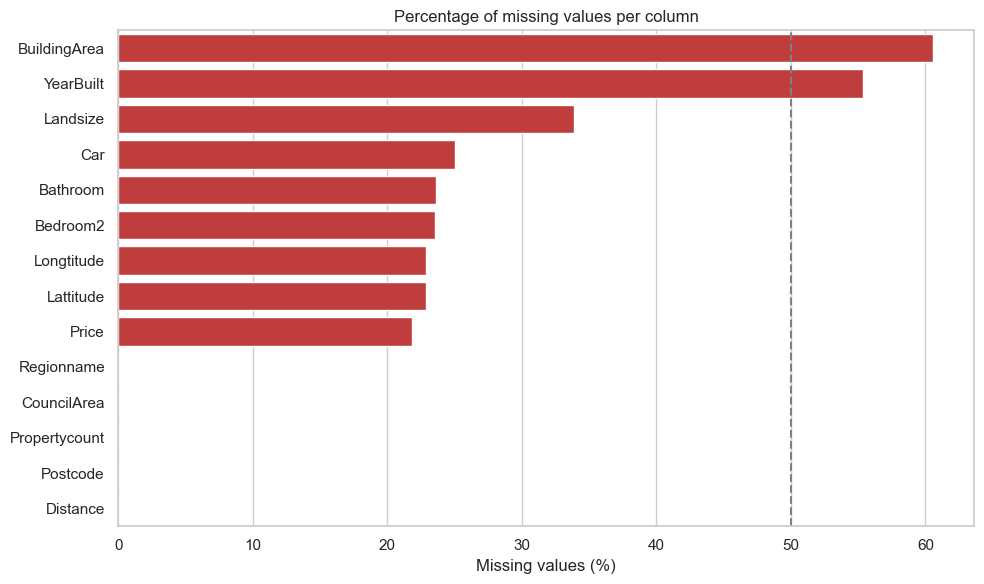

In [75]:
# Easy to understand this with a chart if there is any missing data.

fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

# Can decide what columns to drop based on this analysis.

### 3.e. (i) Drop irrelevant and inconsistent columns and rows. 

In [76]:
# Drop BuildingArea (60.58% missing), Substituted with Landsize for further analysis.
df_clean = df_clean.drop(columns=["BuildingArea"])
df_clean.shape  # should now show 20 columns

(34857, 20)

In [77]:
# Drop rows where Price is missing
print("Missing Price before:", df_clean["Price"].isna().sum())
print("Rows before:", len(df_clean))

df_clean = df_clean.dropna(subset=["Price"])

print("Missing Price after:", df_clean["Price"].isna().sum())
print("Rows after:", len(df_clean))


Missing Price before: 7610
Rows before: 34857
Missing Price after: 0
Rows after: 27247


df_clean now has 27,247 rows and 20 columns
Figure saved to figures\02_missing_values_after_cleaning.png


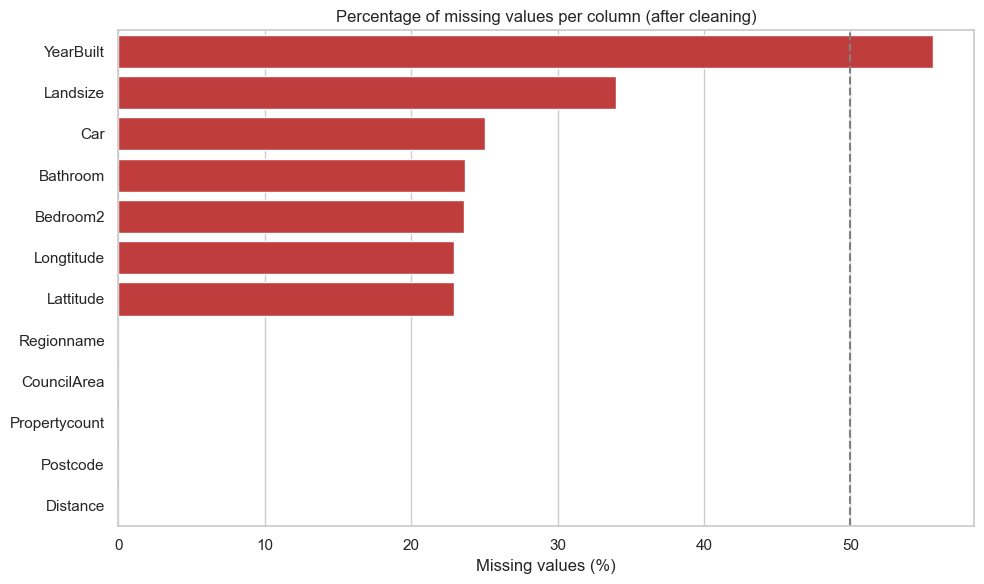

,n_missing,pct_missing
YearBuilt,15163,55.65
Landsize,9265,34.00
Car,6824,25.04
Bathroom,6447,23.66
Bedroom2,6441,23.64
Longtitude,6254,22.95
Lattitude,6254,22.95
Regionname,3,0.01
CouncilArea,3,0.01
Propertycount,3,0.01


In [78]:
# Missing values AFTER removing BuildingArea and rows with missing Price.
# Recalculate the report from df_clean so the chart shows the data as it is now.
missing_after = missing_report(df_clean)
print(f"df_clean now has {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns")

# Only plot the columns that still have at least one missing value
missing_after_to_plot = missing_after[missing_after["pct_missing"] > 0]

if missing_after_to_plot.empty:
    print("No missing values left in df_clean.")
else:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=missing_after_to_plot, x="pct_missing", y=missing_after_to_plot.index, color="tab:red", ax=ax)
    ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
    ax.set_title("Percentage of missing values per column (after cleaning)")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
    plt.tight_layout()
    save_fig("02_missing_values_after_cleaning")
    plt.show()

missing_after_to_plot


In [79]:
# Drop rows where YearBuilt is missing
print("Missing YearBuilt before:", df_clean["YearBuilt"].isna().sum())
print("Rows before:", len(df_clean))

df_clean = df_clean.dropna(subset=["YearBuilt"])

print("Missing YearBuilt after:", df_clean["YearBuilt"].isna().sum())
print("Rows after:", len(df_clean))


Missing YearBuilt before: 15163
Rows before: 27247
Missing YearBuilt after: 0
Rows after: 12084


df_clean now has 12,084 rows and 20 columns
Figure saved to figures\03_missing_values_all_columns.png


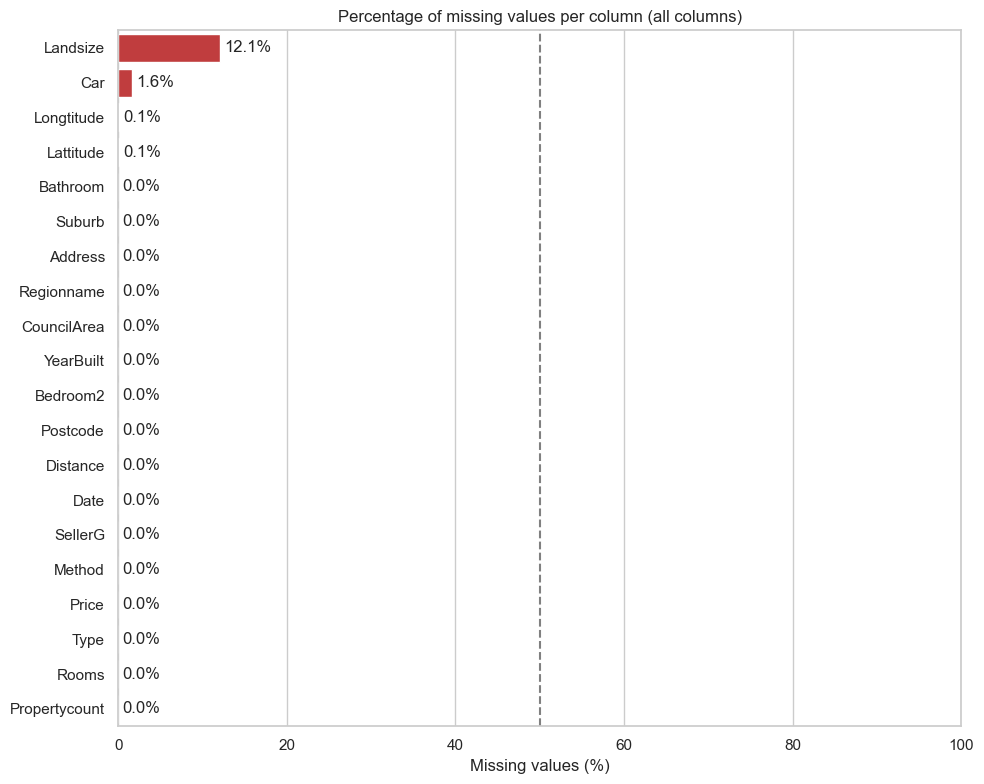

,n_missing,pct_missing
Landsize,1463,12.11
Car,196,1.62
Longtitude,8,0.07
Lattitude,8,0.07
Bathroom,1,0.01
Suburb,0,0.00
Address,0,0.00
Regionname,0,0.00
CouncilArea,0,0.00
YearBuilt,0,0.00


In [80]:
# Missing values for ALL columns (including those with 0 missing)
missing_all = missing_report(df_clean)
print(f"df_clean now has {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns")

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=missing_all, x="pct_missing", y=missing_all.index, color="tab:red", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)   # show the % next to every bar, even 0
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_xlim(0, 100)                            # fixed scale so charts are easy to compare
ax.set_title("Percentage of missing values per column (all columns)")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("03_missing_values_all_columns")
plt.show()

missing_all


### 3.e. (ii) Imputation done to fill missing data.

In [81]:
# Fill missing Car values with the median
print("Missing Car before:", df_clean["Car"].isna().sum())

car_median = df_clean["Car"].median()
df_clean["Car"] = df_clean["Car"].fillna(car_median)

print(f"Filled with median: {car_median}")
print("Missing Car after:", df_clean["Car"].isna().sum())


Missing Car before: 196
Filled with median: 2.0
Missing Car after: 0


### 3.f. (i) Fix inconsistent data types

Give the date format. 
1. Date is day/month/year. Plain pd.to_datetime() can read 3/09/2016 as March 9 instead of September 3, so the code passes format="%d/%m/%Y".
2. Use "Int64", not "int". Plain int fails if any NaN are left, for example in Bathroom or Bedroom2 if you haven't filled them yet. Int64 allows missing values.
3. Postcode becomes text so it isn't treated as a number. An average postcode means nothing.
4. Two column names are misspelled: Lattitude and Longtitude. They aren't data type problems, but you can fix them in step b, "Tidy column names":

In [82]:
# Fix inconsistent data types
print("--- Before ---")
print(df_clean.dtypes)

# 1. Date: text -> datetime. The dates are day/month/year (3/09/2016 = 3 Sep 2016).
df_clean["Date"] = pd.to_datetime(df_clean["Date"], format="%d/%m/%Y")

# 2. Postcode: a label, not a number to average -> string
df_clean["Postcode"] = df_clean["Postcode"].astype("Int64").astype("string")

# 3. Counts and years: float -> whole numbers.
#    "Int64" (capital I) still allows missing values, so it won't crash if any NaN are left.
int_cols = ["Car", "Bedroom2", "Bathroom", "YearBuilt", "Propertycount"]
df_clean[int_cols] = df_clean[int_cols].round().astype("Int64")

# 4. Repeated text labels -> category (uses less memory, useful for plotting/grouping)
cat_cols = ["Type", "Method", "Regionname", "CouncilArea"]
df_clean[cat_cols] = df_clean[cat_cols].astype("category")

print("\n--- After ---")
print(df_clean.dtypes)


--- Before ---
Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

--- After ---
Suburb                   object
Address                  object
Rooms                     int64
Type                   category
Price                   float64
Method                 category
SellerG                  object
Date             datetime64[ns]
Distance                float64
Postcode         string[python]
Bedroom2                  Int64
Bathroom                  Int64
Car                       Int64
Landsize                float64
YearBuil

In [83]:
df_clean = df_clean.rename(columns={"Lattitude": "Latitude", "Longtitude": "Longitude"})


In [84]:
# Check new dataset scope.

print(f"Reduced data scope: {len(df_clean)}")
df_clean.head()

Reduced data scope: 12084


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
6,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
11,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
14,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019


In [85]:
# check the info and data types of each column in the cleaned table
df_clean.info()
df_clean.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
Index: 12084 entries, 2 to 34856
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Suburb         12084 non-null  object        
 1   Address        12084 non-null  object        
 2   Rooms          12084 non-null  int64         
 3   Type           12084 non-null  category      
 4   Price          12084 non-null  float64       
 5   Method         12084 non-null  category      
 6   SellerG        12084 non-null  object        
 7   Date           12084 non-null  datetime64[ns]
 8   Distance       12084 non-null  float64       
 9   Postcode       12084 non-null  string        
 10  Bedroom2       12084 non-null  Int64         
 11  Bathroom       12083 non-null  Int64         
 12  Car            12084 non-null  Int64         
 13  Landsize       10621 non-null  float64       
 14  YearBuilt      12084 non-null  Int64         
 15  CouncilArea    12084 non

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Suburb,12084,324,Reservoir,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,12084,11909,25 William St,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,"12,084.00",NaN,NaN,NaN,3.06,1.00,2.00,3.00,4.00,12.00,0.97
Type,12084,3,h,8736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"12,084.00",NaN,NaN,NaN,"1,077,201.64","85,000.00","632,000.00","885,000.00","1,320,000.00","9,000,000.00","671,327.71"
Method,12084,5,S,7655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,12084,278,Nelson,1266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,12084,NaN,NaN,NaN,2017-04-28 09:48:19.304866048,2016-02-04 00:00:00,2016-10-15 00:00:00,2017-06-17 00:00:00,2017-10-07 00:00:00,2018-03-17 00:00:00,NaN
Distance,"12,084.00",NaN,NaN,NaN,11.29,0.00,6.40,10.30,14.00,48.10,6.97
Postcode,12084,199,3073,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.f. (ii) Fix outliers

Figure saved to figures\04_boxplots_before_outliers.png


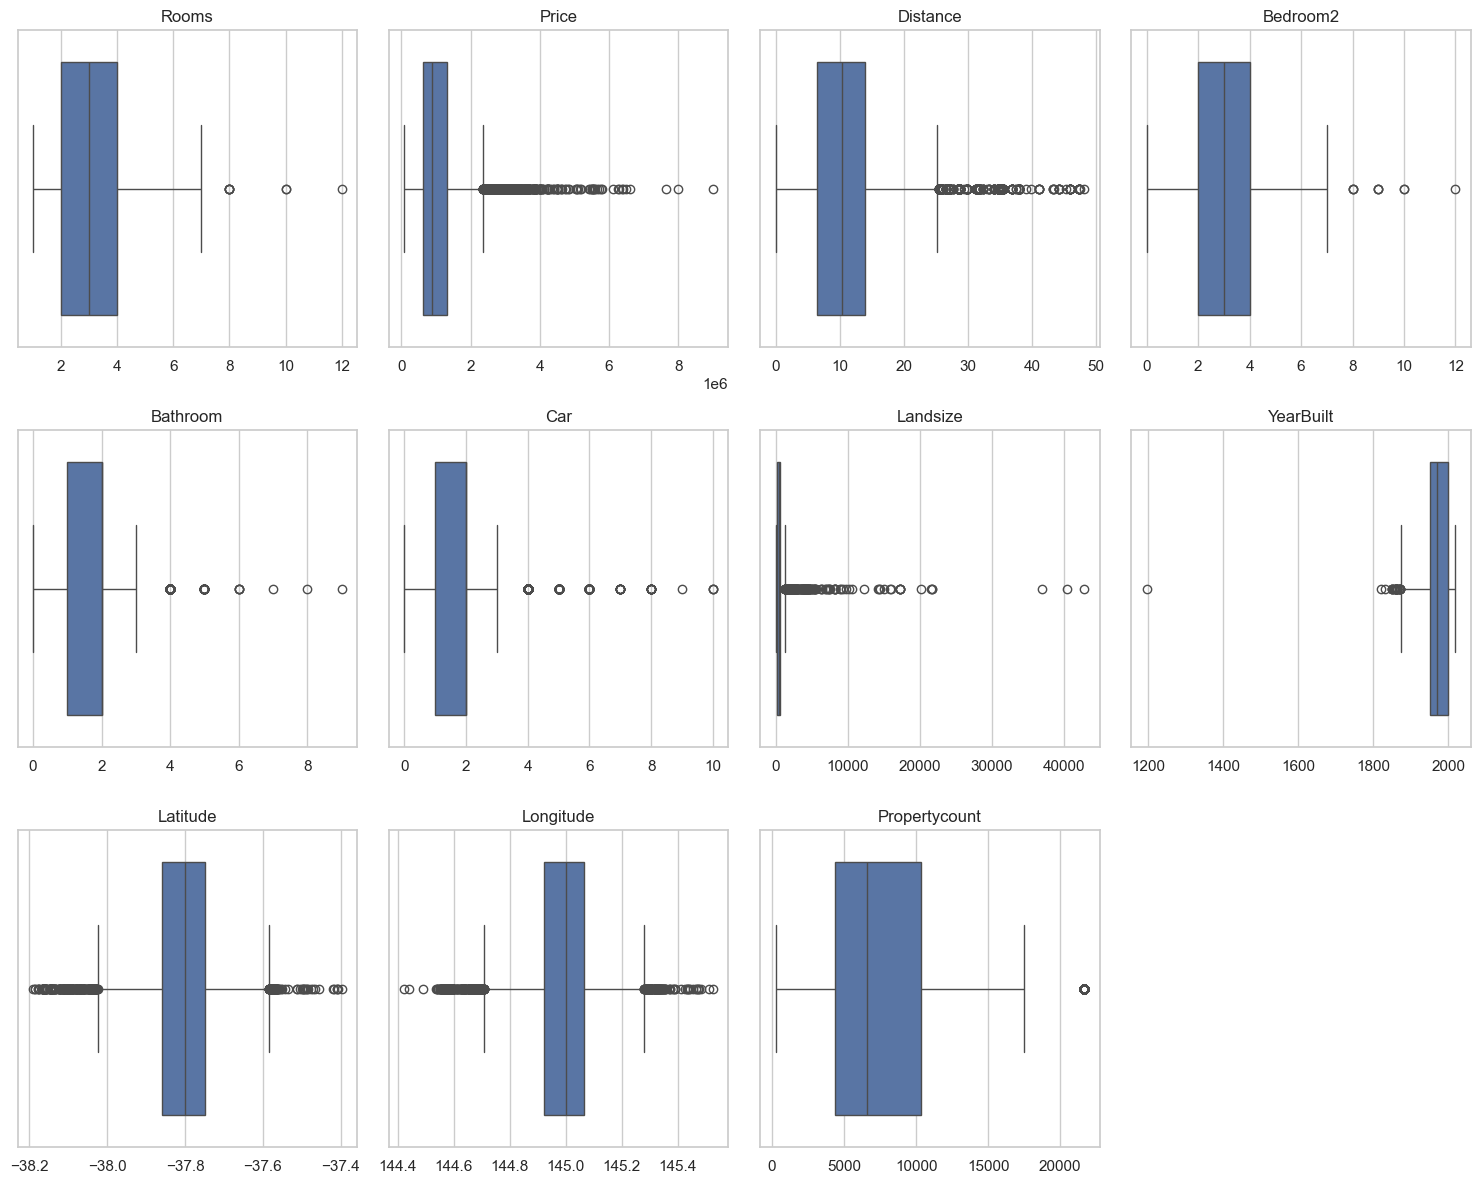

In [86]:
# Inspect the distribution of the numeric columns using boxplots to identify outliers.

# Box -> Middle 50% of values
# Line inside the box -> Median, the middle value
# Whiskers -> Range defined by the boxplot rule (1.5 x IQR)
# Dots beyond the whiskers -> Potential outliers to investigate

def plot_boxplots(data, name):
    num_cols = data.select_dtypes(include="number").columns.tolist()
    n_rows = int(np.ceil(len(num_cols) / 4))

    fig, axes = plt.subplots(n_rows, 4, figsize=(15, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(num_cols):
        sns.boxplot(x=data[col].astype(float), ax=axes[i])
        axes[i].set_title(col)
        axes[i].set_xlabel("")

    # Turn off the empty axes in the last row
    for j in range(len(num_cols), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    save_fig(name)
    plt.show()

plot_boxplots(df_clean, "04_boxplots_before_outliers")


In [87]:
# Fix outliers
rows_before = len(df_clean)

# 1. Remove impossible / unrealistic values (rules based on what a house can be).
#    Missing values are kept (they are handled by imputation, not here).
rules = {
    "Rooms":     (1, 10),
    "Bedroom2":  (0, 10),
    "Bathroom":  (1, 8),
    "Car":       (0, 10),
    "YearBuilt": (1800, 2018),   # sales are from 2016-2017, nothing built in the future
}

for col, (low, high) in rules.items():
    keep = (df_clean[col].isna() | df_clean[col].between(low, high)).astype(bool)
    print(f"{col}: removing {(~keep).sum()} rows outside {low}-{high}")
    df_clean = df_clean[keep]

# 2. Landsize: 0 is valid (apartments), but a few huge values (up to 433,014 m²) stretch the data.
#    Cap them at the 99th percentile instead of deleting the rows.
landsize_cap = df_clean["Landsize"].quantile(0.99)
n_capped = (df_clean["Landsize"] > landsize_cap).sum()
df_clean["Landsize"] = df_clean["Landsize"].clip(upper=landsize_cap)
print(f"Landsize: capped {n_capped} values at {landsize_cap:,.0f} m²")

print(f"\nRows before: {rows_before:,} | Rows after: {len(df_clean):,} | Removed: {rows_before - len(df_clean):,}")


Rooms: removing 1 rows outside 1-10
Bedroom2: removing 0 rows outside 0-10
Bathroom: removing 3 rows outside 1-8
Car: removing 0 rows outside 0-10
YearBuilt: removing 2 rows outside 1800-2018
Landsize: capped 107 values at 2,841 m²

Rows before: 12,084 | Rows after: 12,078 | Removed: 6


Figure saved to figures\05_boxplots_after_outliers.png


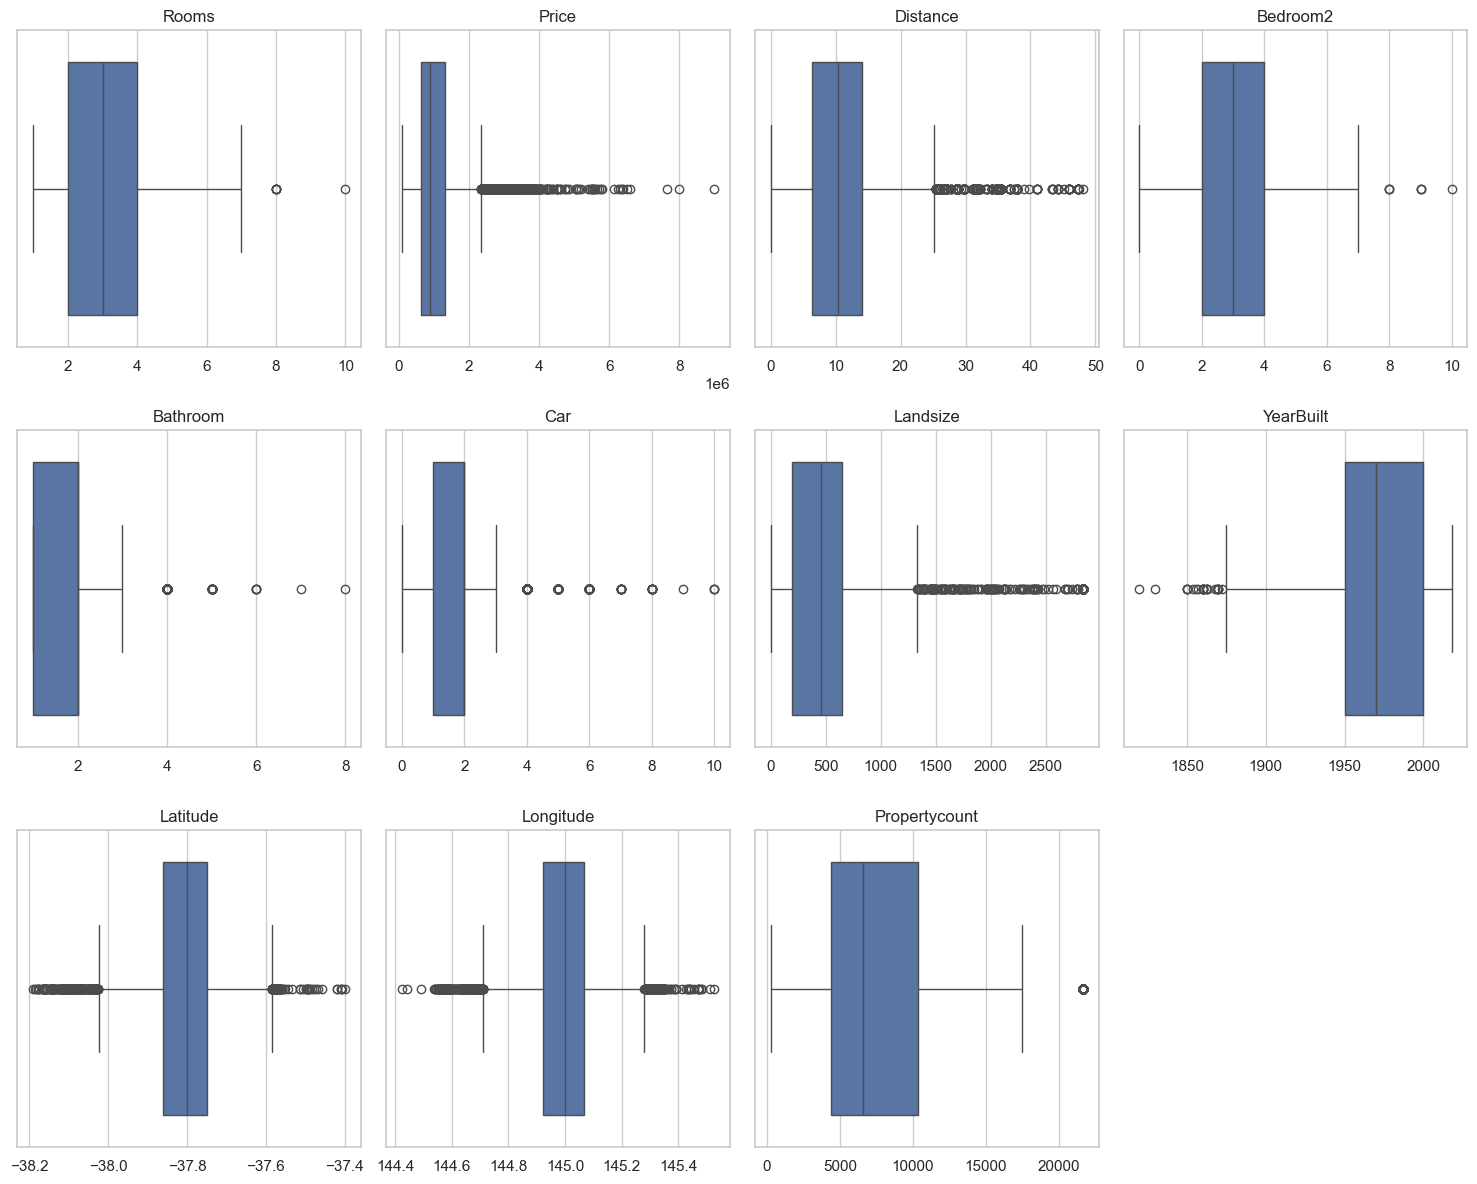

In [88]:
plot_boxplots(df_clean, "05_boxplots_after_outliers")


In [89]:
# This block loops through selected quantitative fields and caps outliers (IQR method)

# Only cap feature columns where extreme values distort the data.
# NOT capped:
#   - Price: the target; expensive houses are real sales
#   - Lattitude / Longtitude: locations, not measurements
#   - Propertycount: number of properties in the suburb, not a property feature
#   - YearBuilt: already cleaned with a 1800-2018 rule; old houses are real
cols_to_cap = ["Rooms", "Distance", "Bedroom2", "Bathroom", "Car", "Landsize"]

# Keep only the columns that exist in df_clean (in case one was dropped earlier)
cols_to_cap = [col for col in cols_to_cap if col in df_clean.columns]

# Loop through each column and cap outliers
for col in cols_to_cap:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Whole-number columns (Int64) can't hold decimals, so round the bounds outward
    if pd.api.types.is_integer_dtype(df_clean[col]):
        lower_bound = int(np.floor(lower_bound))
        upper_bound = int(np.ceil(upper_bound))

    # Count how many values will be changed
    n_capped = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()

    # Print the calculated boundaries for transparency
    print(f"Column '{col}' Bounds -> Lower: {lower_bound:.2f}, Upper: {upper_bound:.2f} | Capped: {n_capped}")

    # Cap values outside the bounds
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)

# Check the result
print(df_clean[cols_to_cap].describe().T)
df_clean.head(10)


Column 'Rooms' Bounds -> Lower: -1.00, Upper: 7.00 | Capped: 6
Column 'Distance' Bounds -> Lower: -5.00, Upper: 25.40 | Capped: 571
Column 'Bedroom2' Bounds -> Lower: -1.00, Upper: 7.00 | Capped: 7
Column 'Bathroom' Bounds -> Lower: -1.00, Upper: 4.00 | Capped: 36
Column 'Car' Bounds -> Lower: -1.00, Upper: 4.00 | Capped: 150
Column 'Landsize' Bounds -> Lower: -484.00, Upper: 1332.00 | Capped: 270
             count   mean    std  min    25%    50%    75%      max
Rooms    12,078.00   3.06   0.96 1.00   2.00   3.00   4.00     7.00
Distance 12,078.00  10.97   6.02 0.00   6.40  10.30  14.00    25.40
Bedroom2 12,078.00   3.05   0.96 0.00   2.00   3.00   4.00     7.00
Bathroom 12,077.00   1.63   0.69 1.00   1.00   2.00   2.00     4.00
Car      12,078.00   1.67   0.87 0.00   1.00   2.00   2.00     4.00
Landsize 10,615.00 450.33 310.32 0.00 197.00 460.00 651.00 1,332.00


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
6,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019
11,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
14,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
18,Abbotsford,10 Valiant St,2,h,"1,097,000.00",S,Biggin,2016-10-08,2.50,3067,3,1,2,220.00,1900,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019
24,Abbotsford,40 Nicholson St,3,h,"1,350,000.00",VB,Nelson,2016-11-12,2.50,3067,3,2,2,214.00,2005,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
25,Abbotsford,123/56 Nicholson St,2,u,"750,000.00",S,Biggin,2016-11-12,2.50,3067,2,2,1,0.00,2009,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
30,Abbotsford,16 William St,2,h,"1,310,000.00",S,Jellis,2016-10-15,2.50,3067,2,1,2,238.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019
32,Abbotsford,42 Henry St,3,h,"1,200,000.00",S,Jellis,2016-07-16,2.50,3067,3,2,1,113.00,1880,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019


Figure saved to figures\06_boxplots_affected_columns.png


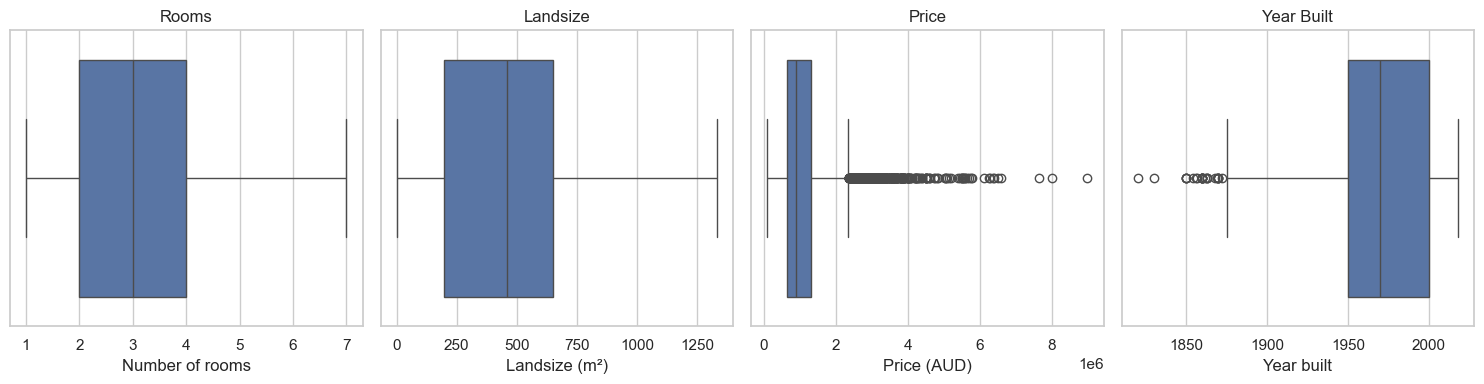

In [90]:
# Re-creating the box plots as before to demonstrate outlier capping:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# 1. Rooms
sns.boxplot(x=df_clean["Rooms"].astype(float), ax=axes[0])
axes[0].set_title("Rooms")
axes[0].set_xlabel("Number of rooms")

# 2. Landsize
sns.boxplot(x=df_clean["Landsize"].astype(float), ax=axes[1])
axes[1].set_title("Landsize")
axes[1].set_xlabel("Landsize (m²)")

# 3. Price
sns.boxplot(x=df_clean["Price"].astype(float), ax=axes[2])
axes[2].set_title("Price")
axes[2].set_xlabel("Price (AUD)")

# 4. YearBuilt
sns.boxplot(x=df_clean["YearBuilt"].astype(float), ax=axes[3])
axes[3].set_title("Year Built")
axes[3].set_xlabel("Year built")

plt.tight_layout()
save_fig("06_boxplots_affected_columns")
plt.show()


In [91]:
# Initiating missing value analysis
missing_report(df_clean).head(12)

,n_missing,pct_missing
Landsize,1463,12.11
Longitude,8,0.07
Latitude,8,0.07
Bathroom,1,0.01
Suburb,0,0.00
Address,0,0.00
Regionname,0,0.00
CouncilArea,0,0.00
YearBuilt,0,0.00
Car,0,0.00


# 4. **Feature Engineering**     
Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready 

In [92]:
# Feature Engineering
# 4.a. Temporal Features: Extract sale year and month from Date
#    (Date is day/month/year; if it is already datetime this line just keeps it as is)
df_clean["Date"] = pd.to_datetime(df_clean["Date"], format="%d/%m/%Y")
df_clean["SaleYear"] = df_clean["Date"].dt.year
df_clean["SaleMonth"] = df_clean["Date"].dt.month

# Age of the house at the moment it was sold
df_clean["HouseAge"] = df_clean["SaleYear"] - df_clean["YearBuilt"]

# 4.b. Property Ratios & Indicators:
# How much land each room has (spacious vs. compact properties)
df_clean["LandPerRoom"] = df_clean["Landsize"] / df_clean["Rooms"]

# Bathrooms relative to rooms (higher = more comfortable / higher-end property)
df_clean["BathPerRoom"] = df_clean["Bathroom"] / df_clean["Rooms"]

# Does the property have at least one car space? (1 = yes, 0 = no)
df_clean["HasCarSpace"] = (df_clean["Car"] > 0).astype("Int64")

# Is the property a house (h) rather than a unit (u) or townhouse (t)? (1 = yes, 0 = no)
df_clean["IsHouse"] = (df_clean["Type"] == "h").astype(int)

# 4.c. Location Feature:
# Group distance to the CBD into zones
df_clean["DistanceZone"] = pd.cut(
    df_clean["Distance"],
    bins=[-0.1, 5, 15, df_clean["Distance"].max()],
    labels=["Inner (0-5 km)", "Middle (5-15 km)", "Outer (15+ km)"]
)

# Display the first few rows with the newly created features
display(df_clean[["Suburb", "SaleYear", "SaleMonth", "HouseAge", "LandPerRoom",
                  "BathPerRoom", "HasCarSpace", "IsHouse", "DistanceZone"]].head())


,Suburb,SaleYear,SaleMonth,HouseAge,LandPerRoom,BathPerRoom,HasCarSpace,IsHouse,DistanceZone
2,Abbotsford,2016,2,116,78.00,0.50,0,1,Inner (0-5 km)
4,Abbotsford,2017,3,117,44.67,0.67,0,1,Inner (0-5 km)
6,Abbotsford,2016,6,2,30.00,0.25,1,1,Inner (0-5 km)
11,Abbotsford,2016,5,106,81.67,0.67,0,1,Inner (0-5 km)
14,Abbotsford,2016,10,126,128.00,0.50,1,1,Inner (0-5 km)


# 5. Comparing raw and clean datasets

In [93]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,"34,857.00","12,078.00"
columns,21.00,28.00
numeric columns,13.00,18.00
average % missing,13.79,0.87
memory (MB),20.23,4.72


# 6. **(EDA)** 
Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

Steps:      
    a. **Descriptive Analysis**:   
    b. **Univariate**: one variable at a time: numerical variables
    c. **Univariate**: one variable at a time  
    d. **Bivariate**: two variables together       
    e. **Multivariate**: several variables at once    
        - Correlation

## 6.a. Descriptive Statistics 

In [94]:
key_numeric = df_clean.select_dtypes(include="number").columns.tolist()
key_numeric

stats = df_clean[key_numeric].describe().T

stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
Rooms,"12,078.00",3.06,0.96,1.00,2.00,3.00,4.00,7.00,0.20
Price,"12,078.00","1,077,092.20","671,384.25","85,000.00","632,000.00","885,000.00","1,320,000.00","9,000,000.00",2.41
Distance,"12,078.00",10.97,6.02,0.00,6.40,10.30,14.00,25.40,0.72
Bedroom2,"12,078.00",3.05,0.96,0.00,2.00,3.00,4.00,7.00,0.20
Bathroom,"12,077.00",1.63,0.69,1.00,1.00,2.00,2.00,4.00,0.87
Car,"12,078.00",1.67,0.87,0.00,1.00,2.00,2.00,4.00,0.63
Landsize,"10,615.00",450.33,310.32,0.00,197.00,460.00,651.00,"1,332.00",0.51
YearBuilt,"12,078.00","1,966.67",36.09,"1,820.00","1,950.00","1,970.00","2,000.00","2,018.00",-0.59
Latitude,"12,070.00",-37.81,0.09,-38.19,-37.86,-37.80,-37.75,-37.40,-0.30
Longitude,"12,070.00",144.99,0.12,144.42,144.92,145.00,145.07,145.53,-0.35


## 6.b. Univariate Analysis

Figure saved to figures\08_univariate_numeric.png


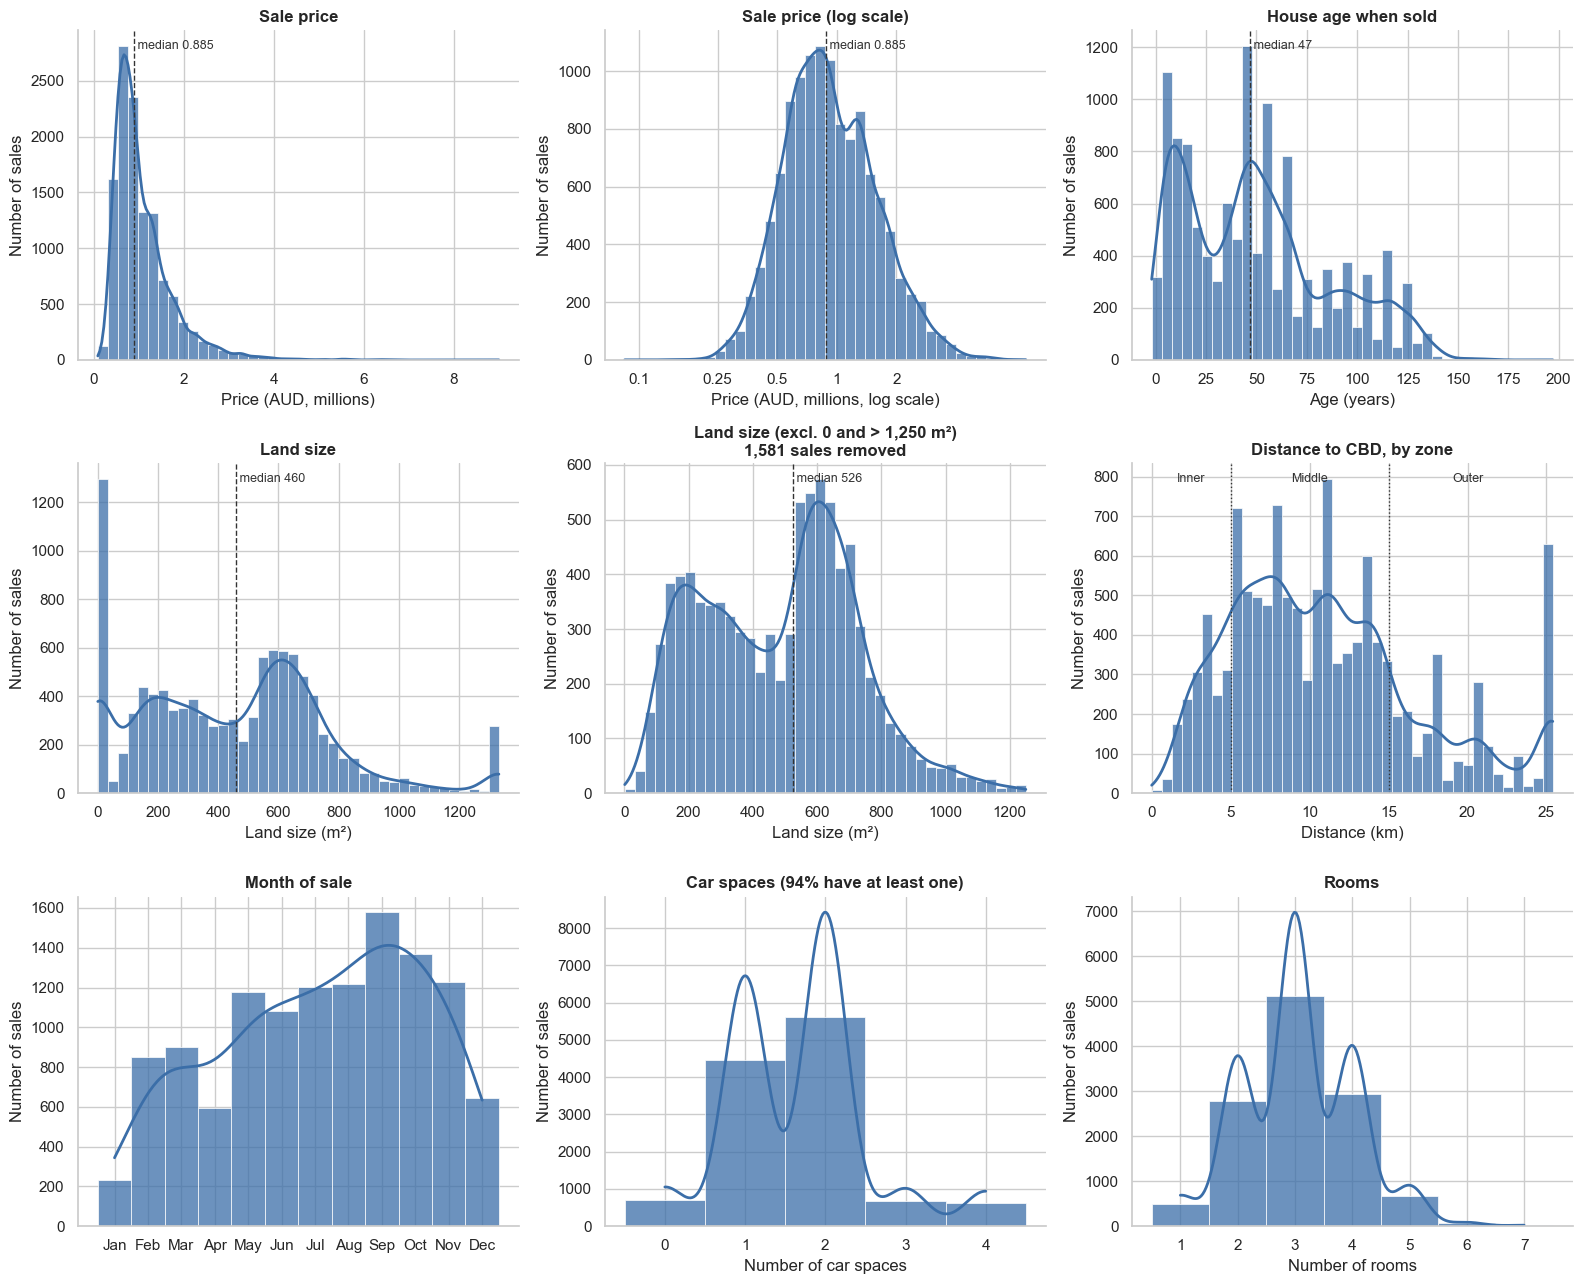

In [95]:
# Univariate Analysis (1/3): numeric columns -> histogram + KDE line
# Histogram   = how many sales fall in each range of values
# KDE line    = smoothed version of the histogram (the overall "shape" of the distribution)
# Dashed line = median (the middle value; not pulled around by very expensive houses)

BAR_COLOR = "#3b6ea8"   # one color for every chart: each plot shows a single variable
INK = "#333333"         # text and reference lines
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Land size limits for the "trimmed" plot: 0 m² (mostly units) and the values near the cap pile up
LAND_MIN, LAND_MAX = 0, 1250

# (column, title, x-axis label, kind)
# kind = "continuous" -> normal histogram with 40 bins
#        "discrete"   -> one bar per whole number (months, car spaces, rooms)
#        "log"        -> logarithmic x-axis: spreads out cheap sales, squeezes the expensive tail
#        "trimmed"    -> extreme values removed before plotting
num_plots = [
    ("Price",     "Sale price",                      "Price (AUD, millions)",           "continuous"),
    ("Price",     "Sale price (log scale)",          "Price (AUD, millions, log scale)", "log"),
    ("HouseAge",  "House age when sold",             "Age (years)",                     "continuous"),
    ("Landsize",  "Land size",                       "Land size (m²)",                  "continuous"),
    ("Landsize",  f"Land size (excl. 0 and > {LAND_MAX:,} m²)", "Land size (m²)",       "trimmed"),
    ("Distance",  "Distance to CBD, by zone",        "Distance (km)",                   "continuous"),
    ("SaleMonth", "Month of sale",                   "",                                "discrete"),
    ("Car",       "Car spaces",                      "Number of car spaces",            "discrete"),
    ("Rooms",     "Rooms",                           "Number of rooms",                 "discrete"),
]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()
ax_by_col = {}   # remember which subplot shows which column (for the extra touches below)

for ax, (col, title, xlabel, kind) in zip(axes, num_plots):
    ax_by_col.setdefault(col, ax)
    values = df_clean[col].dropna().astype(float)
    if col == "Price":
        values = values / 1e6   # show millions so the axis is readable
    if kind == "trimmed":
        n_before = len(values)
        values = values[(values > LAND_MIN) & (values <= LAND_MAX)]
        title += f"\n{n_before - len(values):,} sales removed"

    discrete = kind == "discrete"
    sns.histplot(
        x=values, ax=ax, kde=True, discrete=discrete,
        bins="auto" if discrete else 40,
        log_scale=(kind == "log"),   # bins and KDE are computed on the log scale too
        color=BAR_COLOR, edgecolor="white", linewidth=0.5, alpha=0.75,
        kde_kws={"bw_adjust": 2 if discrete else 1},   # smoother line for whole-number columns
        line_kws={"linewidth": 2},
    )

    # Median reference line (skipped for whole-number columns, where it is just one of the bars)
    if not discrete and col != "Distance":
        median = values.median()
        ax.axvline(median, color=INK, linestyle="--", linewidth=1)
        ax.text(median, 0.97, f" median {median:,.3g}", transform=ax.get_xaxis_transform(),
                ha="left", va="top", fontsize=9, color=INK)

    # Log axis: readable price ticks instead of 10^-1, 10^0
    if kind == "log":
        ticks = [0.1, 0.25, 0.5, 1, 2]
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"{t:g}" for t in ticks])
        ax.minorticks_off()

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of sales")

# Distance: mark the three zones used in the DistanceZone feature
ax = ax_by_col["Distance"]
for edge in [5, 15]:
    ax.axvline(edge, color=INK, linestyle=":", linewidth=1)
for x, label in [(2.5, "Inner"), (10, "Middle"), (20, "Outer")]:
    ax.text(x, 0.97, label, transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=9, color=INK)

# Month of sale: show month names instead of 1-12
ax_by_col["SaleMonth"].set_xticks(range(1, 13))
ax_by_col["SaleMonth"].set_xticklabels(MONTHS)

# Car spaces: add the share of properties with at least one space (HasCarSpace feature)
pct_car = df_clean["HasCarSpace"].mean() * 100
ax_by_col["Car"].set_title(f"Car spaces ({pct_car:.0f}% have at least one)", fontweight="bold")
ax_by_col["Car"].set_xticks(range(0, int(df_clean["Car"].max()) + 1))

# Note: Landsize was capped at its upper IQR bound and units often have 0 m²,
# so the full Land size plot has a spike at 0 and a pile-up at the right edge;
# the trimmed plot next to it shows the typical house lot without them.

sns.despine()
plt.tight_layout()
save_fig("08_univariate_numeric")
plt.show()

Figure saved to figures\09_univariate_categorical.png


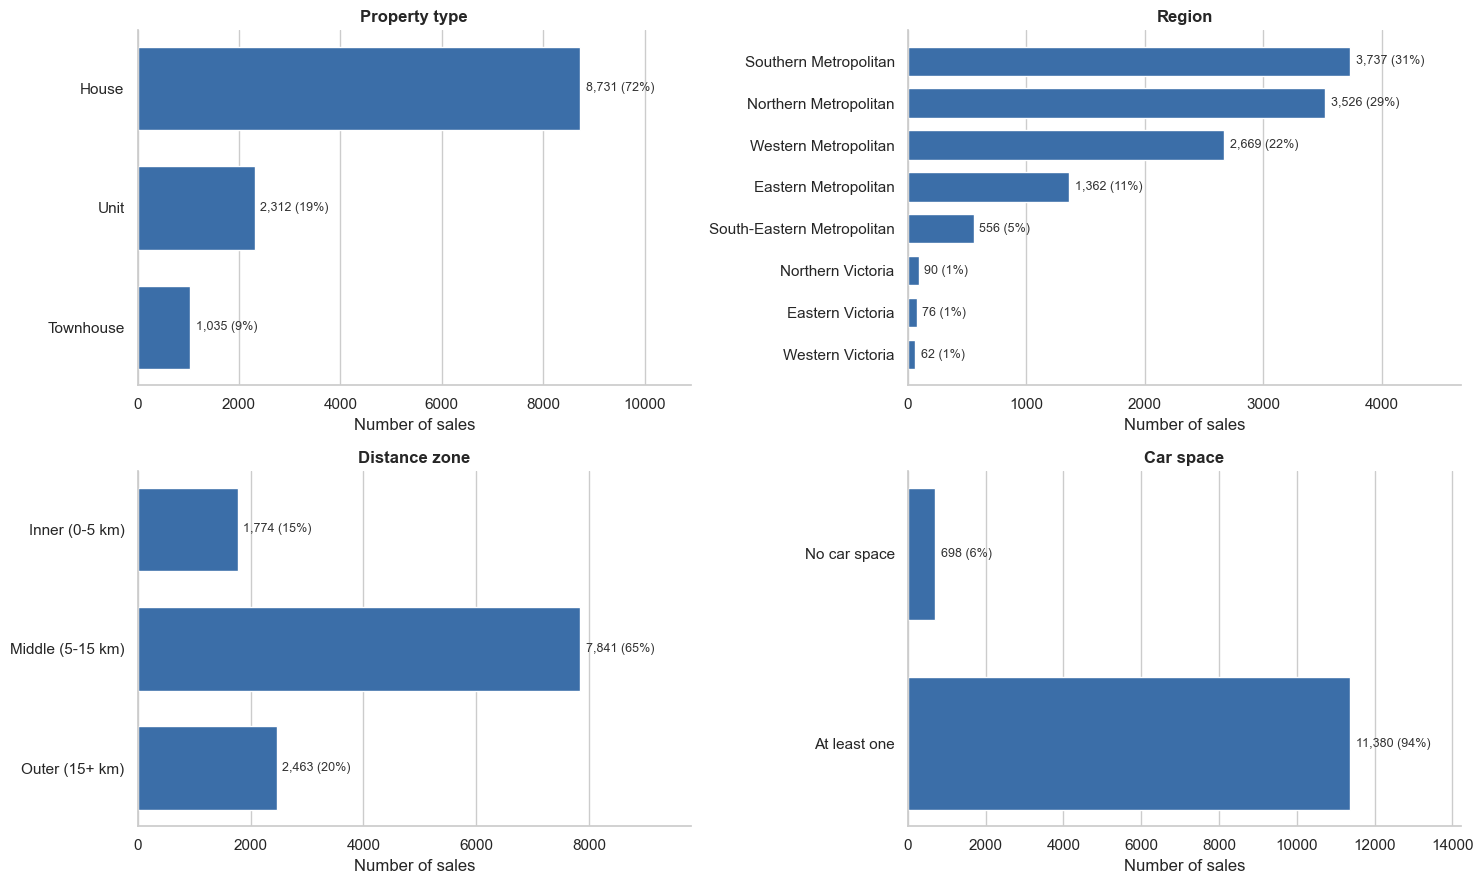

In [96]:
# Univariate Analysis (2/3): categorical columns -> bar chart with count and %
# A KDE line has no meaning for categories (there is nothing "between" House and Unit),
# so these stay as bar charts.

bar_color = "#3b6ea8"

# (column, title, nicer labels, sort by count?)
# DistanceZone and HasCarSpace keep their natural order (inner -> outer, no -> yes)
cat_plots = [
    ("Type",         "Property type", {"h": "House", "u": "Unit", "t": "Townhouse"}, True),
    ("Regionname",   "Region",        None,                                          True),
    ("DistanceZone", "Distance zone", None,                                          False),
    ("HasCarSpace",  "Car space",     {"0": "No car space", "1": "At least one"},    False),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes = axes.flatten()

for ax, (col, title, labels, sort_by_count) in zip(axes, cat_plots):
    counts = df_clean[col].value_counts(sort=sort_by_count)
    if not sort_by_count:
        counts = counts.sort_index()
    counts.index = counts.index.astype(str)
    if labels:
        counts = counts.rename(index=labels)
    pct = counts / counts.sum() * 100

    ax.barh(counts.index, counts.values, color=bar_color, height=0.7)
    ax.invert_yaxis()   # first category on top
    ax.bar_label(ax.containers[0], labels=[f"{n:,} ({p:.0f}%)" for n, p in zip(counts, pct)],
                 padding=4, fontsize=9, color=INK)
    ax.set_xlim(0, counts.max() * 1.25)   # leave room for the labels
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Number of sales")
    ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
save_fig("09_univariate_categorical")
plt.show()

Figure saved to figures\09_univariate_categorical_2.png


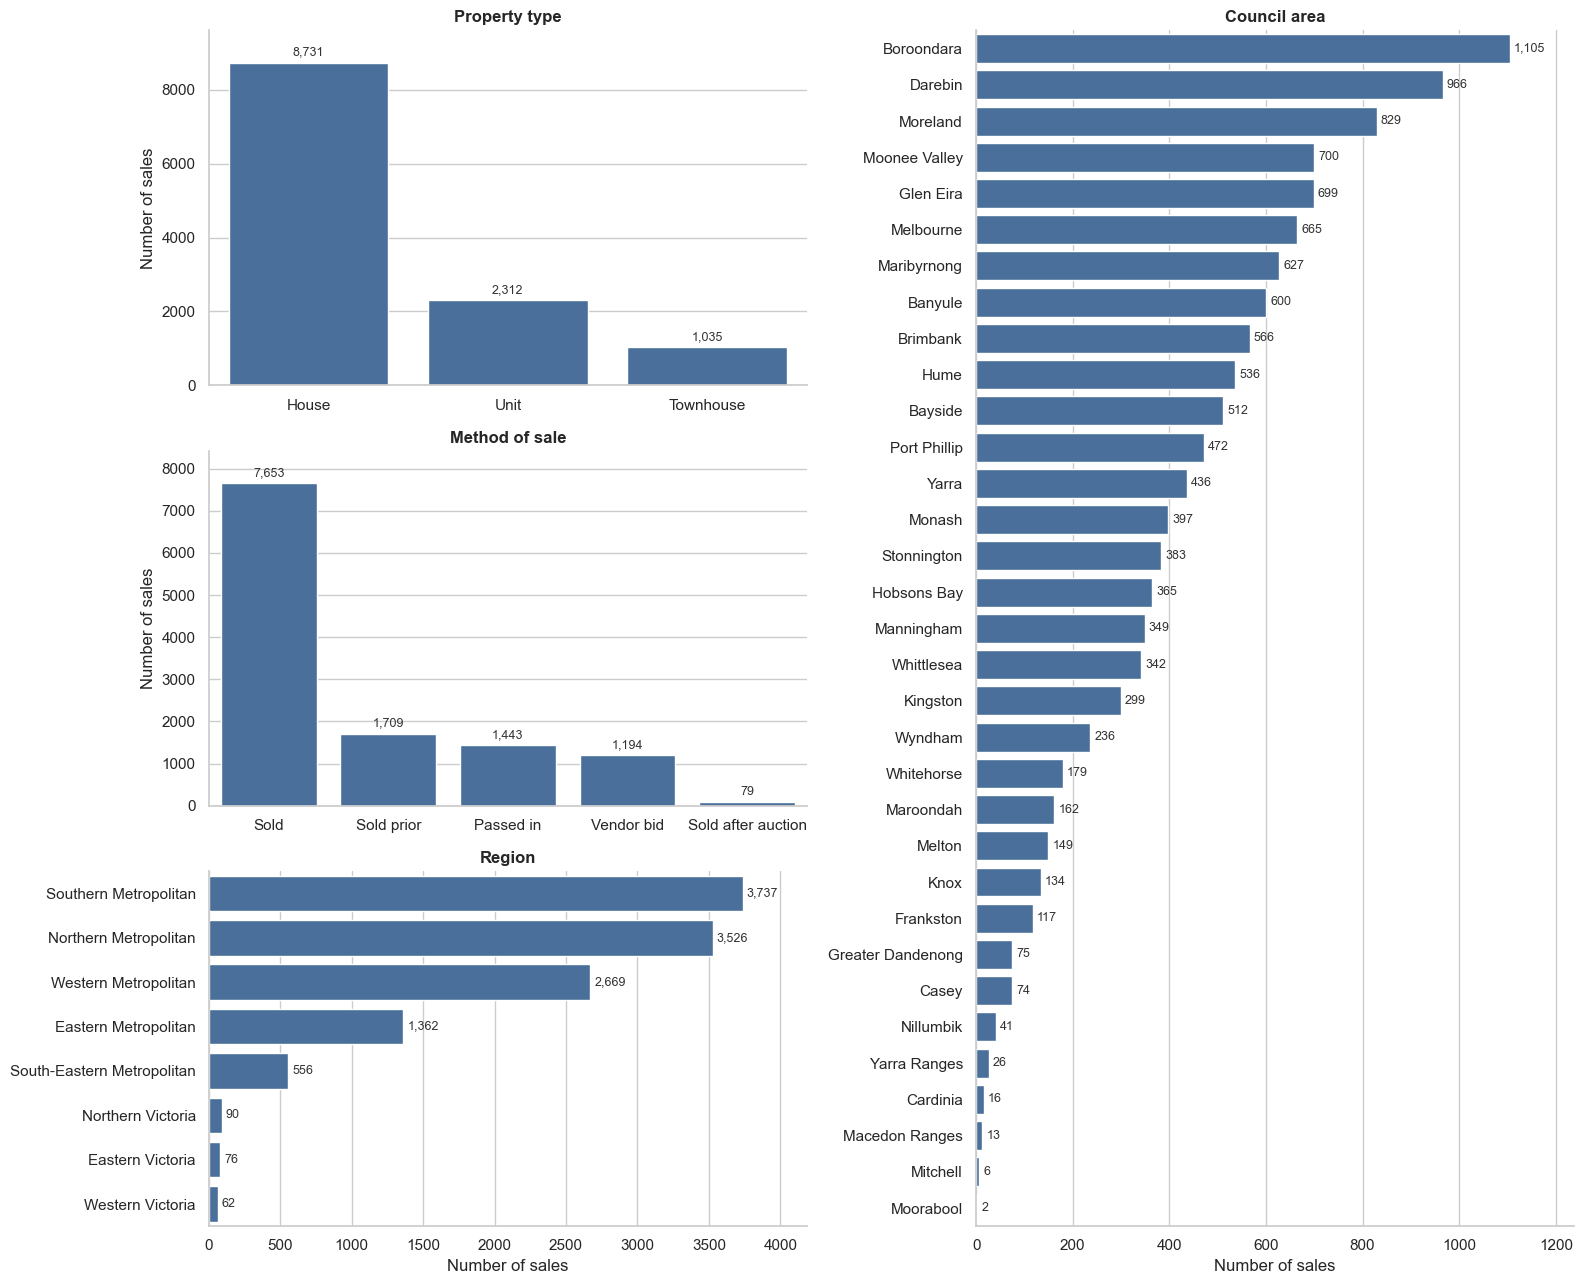

In [97]:
# Univariate Analysis (3/3): categorical columns -> count plots
# A KDE line has no meaning for categories (there is nothing "between" House and Unit),
# so these are bar charts: one bar per category, height = number of sales.

# Readable names for the short codes used in the dataset
type_names = {"h": "House", "u": "Unit", "t": "Townhouse"}
method_names = {"S": "Sold", "SP": "Sold prior", "PI": "Passed in",
                "VB": "Vendor bid", "SA": "Sold after auction"}

# .astype(str) drops unused categories, so no empty bars appear
type_label = df_clean["Type"].astype(str).map(type_names)
method_label = df_clean["Method"].astype(str).map(method_names)
region_label = df_clean["Regionname"].astype(str)
# "Boroondara City Council" -> "Boroondara" (shorter labels, same information)
council_label = df_clean["CouncilArea"].astype(str).str.replace(r" (City|Shire) Council$", "", regex=True)

# Layout: three small charts on the left, council area (33 bars) uses the whole right column
fig = plt.figure(figsize=(16, 13))
grid = fig.add_gridspec(3, 2)
ax_type = fig.add_subplot(grid[0, 0])
ax_method = fig.add_subplot(grid[1, 0])
ax_region = fig.add_subplot(grid[2, 0])
ax_council = fig.add_subplot(grid[:, 1])

# order=... sorts the bars from most to least frequent
sns.countplot(x=type_label, order=type_label.value_counts().index,
              color=BAR_COLOR, ax=ax_type)
ax_type.set_title("Property type", fontweight="bold")
ax_type.set_xlabel("")

sns.countplot(x=method_label, order=method_label.value_counts().index,
              color=BAR_COLOR, ax=ax_method)
ax_method.set_title("Method of sale", fontweight="bold")
ax_method.set_xlabel("")

# Region and council names are long, so these are horizontal (y=...)
sns.countplot(y=region_label, order=region_label.value_counts().index,
              color=BAR_COLOR, ax=ax_region)
ax_region.set_title("Region", fontweight="bold")

sns.countplot(y=council_label, order=council_label.value_counts().index,
              color=BAR_COLOR, ax=ax_council)
ax_council.set_title("Council area", fontweight="bold")

for ax in [ax_type, ax_method]:   # vertical bar charts
    ax.set_ylabel("Number of sales")
    ax.margins(y=0.1)             # room for the count labels above the bars
for ax in [ax_region, ax_council]:   # horizontal bar charts
    ax.set_xlabel("Number of sales")
    ax.set_ylabel("")
    ax.margins(x=0.12)               # room for the count labels after the bars
for ax in [ax_type, ax_method, ax_region, ax_council]:
    ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3, fontsize=9, color=INK)   # count on each bar

sns.despine()
plt.tight_layout()
save_fig("09_univariate_categorical_2")
plt.show()


## 6.c. Bivariate Analysis

Figure saved to figures\10_bivariate_price_by_suburb.png


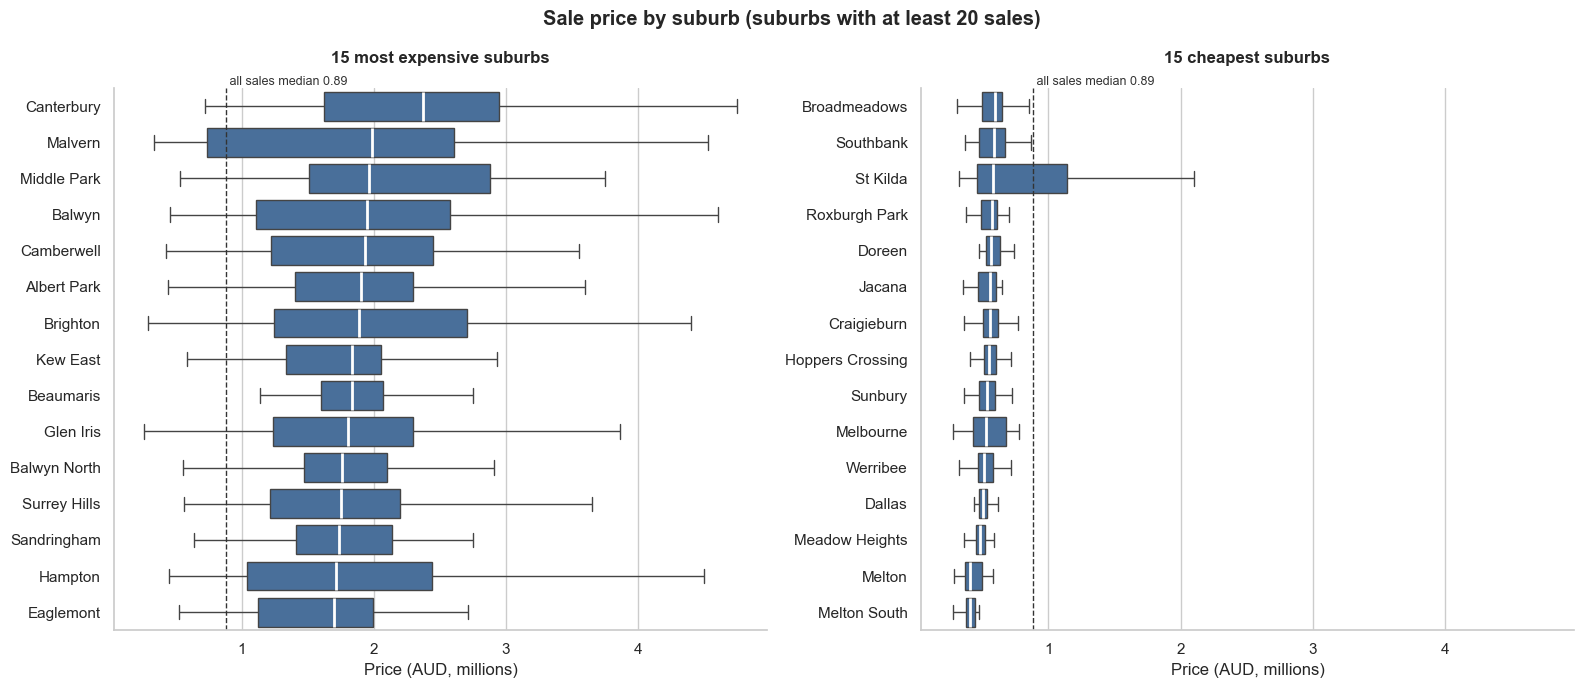

In [98]:
# Bivariate Analysis (1/4): Price by suburb
# Box   = middle 50% of sale prices in that suburb
# White line inside the box = median price
# Dashed line = median price of ALL sales (to compare each suburb against Melbourne overall)
#
# There are 300+ suburbs, too many for one chart, so we compare the 15 most expensive with
# the 15 cheapest (by median). Suburbs with fewer than 20 sales are left out: a median from
# a handful of sales is not reliable.

MIN_SALES = 20
TOP_N = 15

biv = df_clean.assign(PriceM=df_clean["Price"] / 1e6)   # price in millions, as in the univariate plots
price_median_all = biv["PriceM"].median()

def box_by_group(data, x, y, order, ax, overall=None, overall_label=""):
    # Horizontal boxplot of x for each group in y, in the given order (outlier dots hidden)
    sns.boxplot(data=data, x=x, y=y, order=order, color=BAR_COLOR, showfliers=False,
                medianprops={"color": "white", "linewidth": 2}, ax=ax)
    if overall is not None:
        ax.axvline(overall, color=INK, linestyle="--", linewidth=1)
        ax.text(overall, 1.0, f" {overall_label}", transform=ax.get_xaxis_transform(),
                ha="left", va="bottom", fontsize=9, color=INK)
    ax.set_ylabel("")

def highest_and_lowest(value_col):
    # Suburbs with enough sales, ranked by median value_col -> (data, top names, bottom names)
    counts = biv["Suburb"].value_counts()
    data = biv[biv["Suburb"].isin(counts[counts >= MIN_SALES].index)]
    ranked = data.groupby("Suburb")[value_col].median().sort_values(ascending=False)
    return data, ranked.index[:TOP_N], ranked.index[-TOP_N:]

suburb_data, priciest, cheapest = highest_and_lowest("PriceM")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)
for ax, names, title in [(axes[0], priciest, f"{TOP_N} most expensive suburbs"),
                         (axes[1], cheapest, f"{TOP_N} cheapest suburbs")]:
    box_by_group(suburb_data, "PriceM", "Suburb", names, ax,
                 overall=price_median_all, overall_label=f"all sales median {price_median_all:.2f}")
    ax.set_title(title, fontweight="bold", pad=18)
    ax.set_xlabel("Price (AUD, millions)")

fig.suptitle(f"Sale price by suburb (suburbs with at least {MIN_SALES} sales)", fontweight="bold")
sns.despine()
plt.tight_layout()
save_fig("10_bivariate_price_by_suburb")
plt.show()


Figure saved to figures\11_bivariate_price_by_council.png


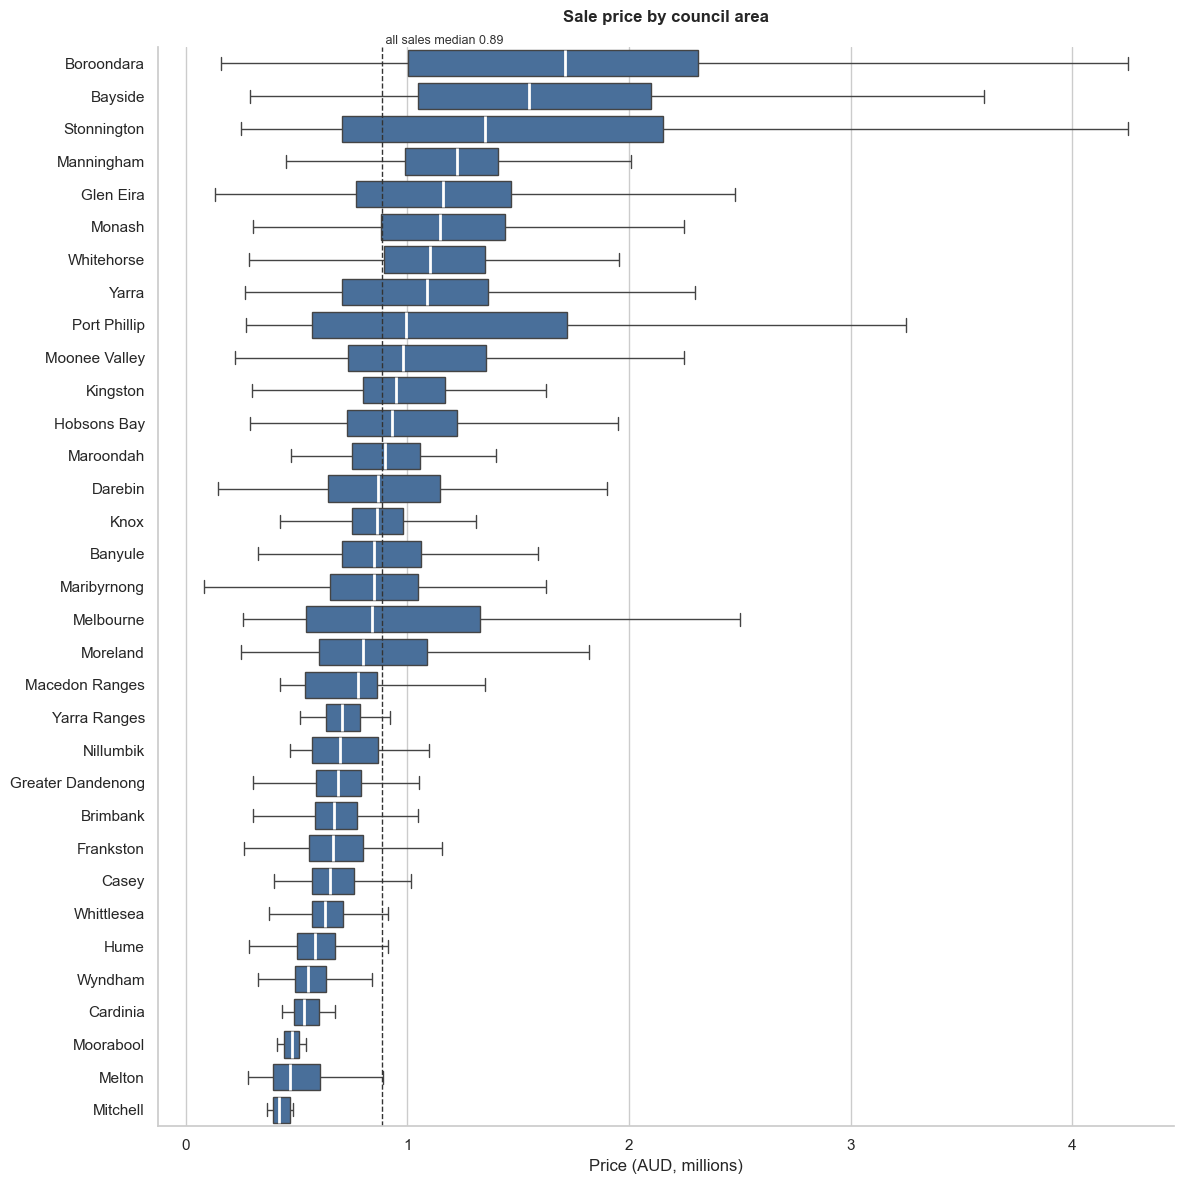

In [99]:
# Bivariate Analysis (2/4): Price by council area
# Same boxplot as for suburbs; all 33 council areas fit, sorted from most to least expensive.

# "Boroondara City Council" -> "Boroondara" (shorter labels, same information)
biv["Council"] = biv["CouncilArea"].astype(str).str.replace(r" (City|Shire) Council$", "", regex=True)
council_order = biv.groupby("Council")["PriceM"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 12))
box_by_group(biv, "PriceM", "Council", council_order, ax,
             overall=price_median_all, overall_label=f"all sales median {price_median_all:.2f}")
ax.set_title("Sale price by council area", fontweight="bold", pad=18)
ax.set_xlabel("Price (AUD, millions)")

sns.despine()
plt.tight_layout()
save_fig("11_bivariate_price_by_council")
plt.show()


Figure saved to figures\12_bivariate_price_vs_land_and_rooms.png


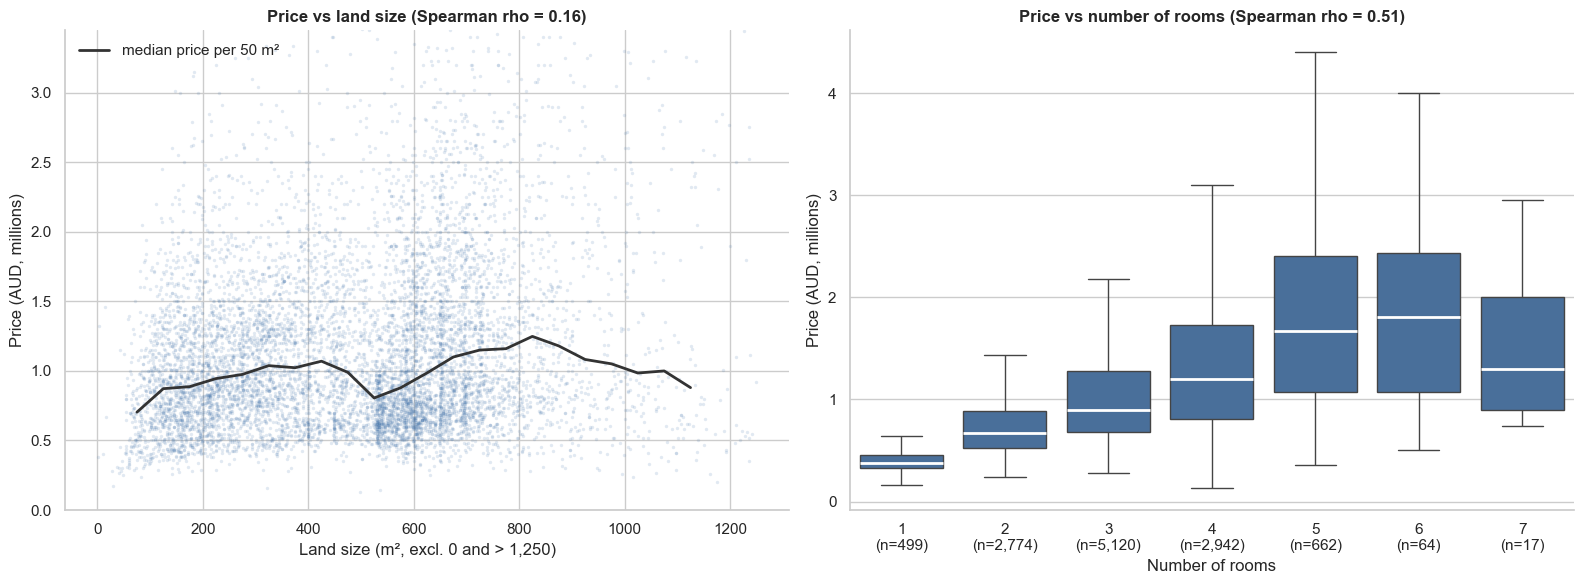

In [100]:
# Bivariate Analysis (3/4): Price vs land size and Price vs number of rooms
# Spearman correlation (rho): -1 to +1, how strongly price goes up (or down) with the other
# variable. It uses ranks, so it is not thrown off by the skewed price distribution.

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Price vs land size: same range as the trimmed univariate plot (LAND_MIN, LAND_MAX).
# 0 m² is left out: those are mostly units, which have no land of their own.
land = biv[(biv["Landsize"] > LAND_MIN) & (biv["Landsize"] <= LAND_MAX)]
rho_land = land["Landsize"].corr(land["PriceM"], method="spearman")

ax = axes[0]
ax.scatter(land["Landsize"], land["PriceM"], s=6, alpha=0.15, color=BAR_COLOR, linewidths=0)
# Median price per 50 m² of land: shows the trend through the cloud of points
# (only bins with at least 30 sales, so a few sales at the edge don't make the line jump)
land_bins = (land["Landsize"] // 50) * 50 + 25
trend = land.groupby(land_bins)["PriceM"].agg(["median", "count"])
trend = trend[trend["count"] >= 30]
ax.plot(trend.index, trend["median"], color=INK, linewidth=2, label="median price per 50 m²")
ax.legend(loc="upper left", frameon=False)
# A few very expensive sales stretch the axis: show up to the 99th percentile of price
ax.set_ylim(0, land["PriceM"].quantile(0.99))
ax.set_title(f"Price vs land size (Spearman rho = {rho_land:.2f})", fontweight="bold")
ax.set_xlabel(f"Land size (m², excl. 0 and > {LAND_MAX:,})")
ax.set_ylabel("Price (AUD, millions)")

# Price vs rooms: one box per number of rooms; the number of sales is shown under each box
rho_rooms = biv["Rooms"].corr(biv["PriceM"], method="spearman")
room_counts = biv["Rooms"].value_counts().sort_index()

ax = axes[1]
sns.boxplot(data=biv, x="Rooms", y="PriceM", order=room_counts.index, color=BAR_COLOR,
            showfliers=False, medianprops={"color": "white", "linewidth": 2}, ax=ax)
ax.set_xticks(range(len(room_counts)))
ax.set_xticklabels([f"{r}\n(n={n:,})" for r, n in room_counts.items()])
ax.set_title(f"Price vs number of rooms (Spearman rho = {rho_rooms:.2f})", fontweight="bold")
ax.set_xlabel("Number of rooms")
ax.set_ylabel("Price (AUD, millions)")

sns.despine()
plt.tight_layout()
save_fig("12_bivariate_price_vs_land_and_rooms")
plt.show()


Figure saved to figures\13_bivariate_age_by_suburb.png


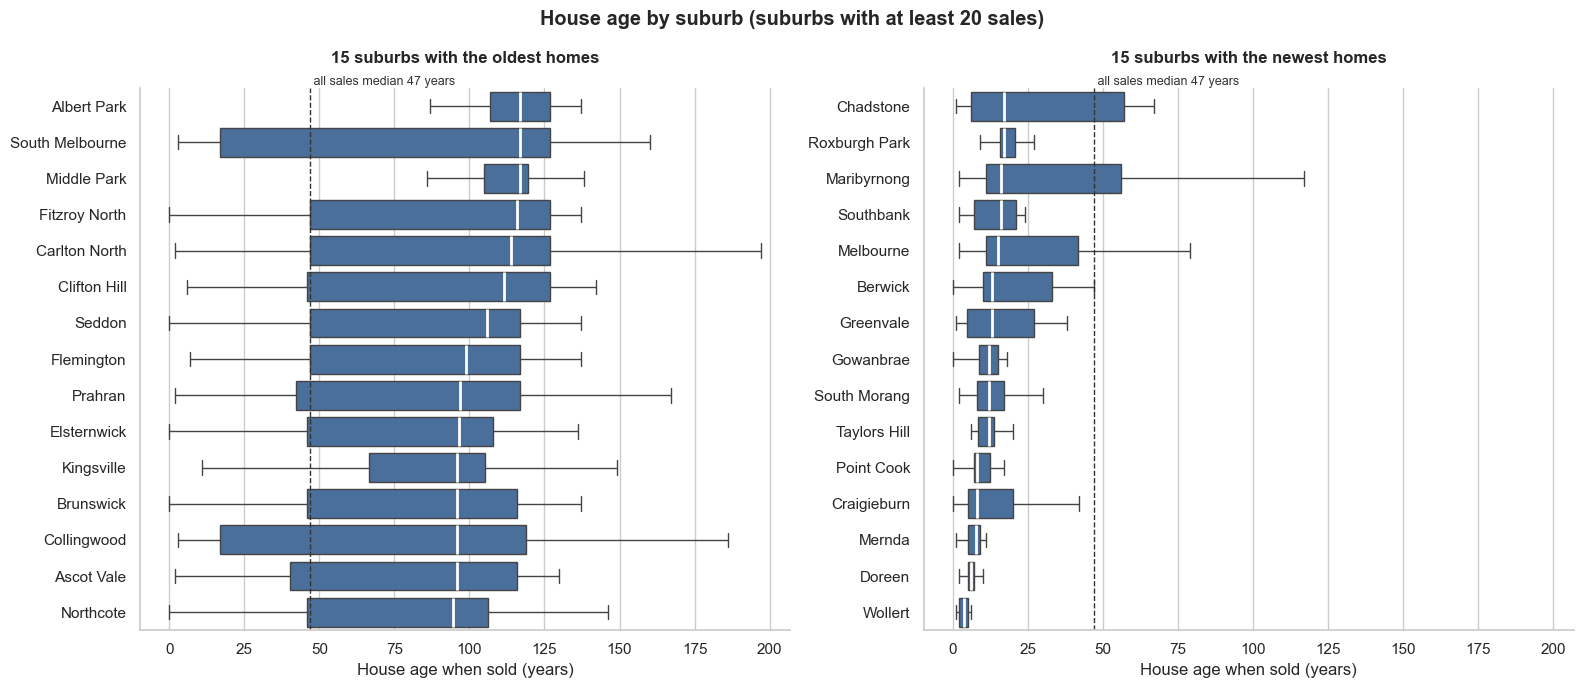

In [101]:
# Bivariate Analysis (4/4): House age by suburb
# Same idea as price by suburb: the 15 suburbs with the oldest homes vs the 15 with the newest
# (by median age when sold), only suburbs with at least MIN_SALES sales.

age_median_all = biv["HouseAge"].median()
suburb_data, oldest, newest = highest_and_lowest("HouseAge")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)
for ax, names, title in [(axes[0], oldest, f"{TOP_N} suburbs with the oldest homes"),
                         (axes[1], newest, f"{TOP_N} suburbs with the newest homes")]:
    box_by_group(suburb_data, "HouseAge", "Suburb", names, ax,
                 overall=age_median_all, overall_label=f"all sales median {age_median_all:.0f} years")
    ax.set_title(title, fontweight="bold", pad=18)
    ax.set_xlabel("House age when sold (years)")

fig.suptitle(f"House age by suburb (suburbs with at least {MIN_SALES} sales)", fontweight="bold")
sns.despine()
plt.tight_layout()
save_fig("13_bivariate_age_by_suburb")
plt.show()


###  Correlation

The **correlation coefficient** measures how strongly two numeric variables move together, from **−1** (one goes up, the other goes down) through **0** (no relation) to **+1** (they go up together).

We use **Spearman** correlation instead of the default (Pearson): it works with the *ranking* of the values, so it is not fooled by skewed distributions and outliers.

A **heatmap** shows the whole correlation matrix as colours. The matrix is symmetric (corr(A, B) = corr(B, A)), so we hide the upper triangle with a **mask**.

Figure saved to figures\14_correlation_heatmap.png


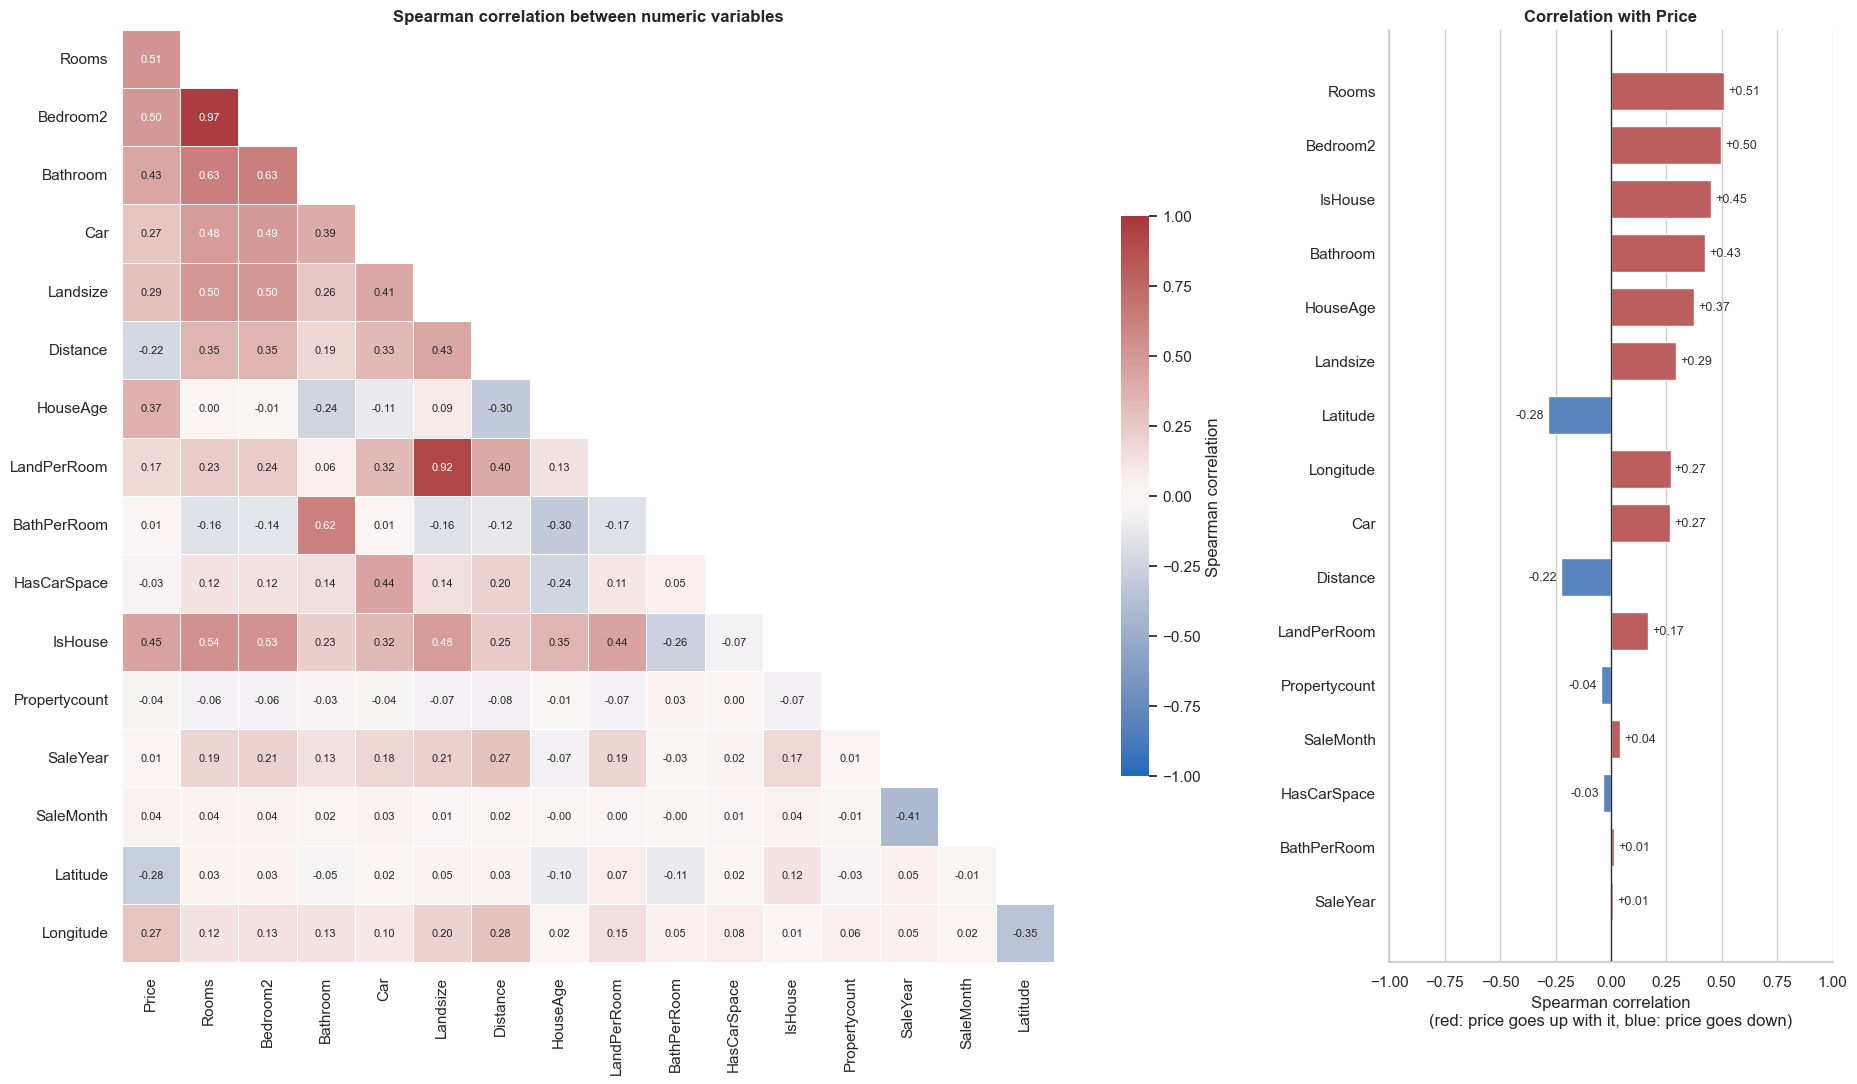

In [102]:
# Correlation: Spearman heatmap of every numeric variable that could affect Price
# Left:  full correlation matrix (lower triangle only)
# Right: just the column for Price, sorted by strength -> which variables matter most for price

corr_cols = ["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "Landsize", "Distance",
             "HouseAge", "LandPerRoom", "BathPerRoom", "HasCarSpace", "IsHouse",
             "Propertycount", "SaleYear", "SaleMonth", "Latitude", "Longitude"]
# YearBuilt is left out: it holds the same information as HouseAge (just with the opposite sign)

# .astype(float): the Int64 columns become normal numbers so .corr() can use them
corr = df_clean[corr_cols].astype(float).corr(method="spearman")

# Drop the first row and last column: after masking they would be empty
corr_lower = corr.iloc[1:, :-1]
# mask = True above the diagonal -> those cells are hidden (they repeat the lower triangle)
mask = np.triu(np.ones_like(corr_lower, dtype=bool), k=1)

# Diverging colours: blue = negative, red = positive, white = 0 (no relation)
corr_cmap = sns.color_palette("vlag", as_cmap=True)

fig = plt.figure(figsize=(20, 11))
grid = fig.add_gridspec(1, 2, width_ratios=[3, 1])
ax_heat = fig.add_subplot(grid[0])
ax_price = fig.add_subplot(grid[1])

sns.heatmap(corr_lower, mask=mask, cmap=corr_cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"shrink": 0.6, "label": "Spearman correlation"}, ax=ax_heat)
ax_heat.set_title("Spearman correlation between numeric variables", fontweight="bold")
ax_heat.grid(False)   # the whitegrid style would draw lines through the cells

# Correlation of each variable with Price, strongest (positive or negative) on top
price_corr = corr["Price"].drop("Price").sort_values(key=abs)
bar_colors = [corr_cmap(0.9) if r > 0 else corr_cmap(0.1) for r in price_corr]

ax_price.barh(price_corr.index, price_corr.values, color=bar_colors, height=0.7)
ax_price.bar_label(ax_price.containers[0], fmt="{:+.2f}", padding=3, fontsize=9, color=INK)
ax_price.axvline(0, color=INK, linewidth=1)
ax_price.set_xlim(-1, 1)
ax_price.set_title("Correlation with Price", fontweight="bold")
ax_price.set_xlabel("Spearman correlation\n(red: price goes up with it, blue: price goes down)")
ax_price.grid(axis="y", visible=False)

sns.despine(ax=ax_price)
plt.tight_layout()
save_fig("14_correlation_heatmap")
plt.show()


## 6.d. Multivariate analysis

Figure saved to figures\15_multivariate_maps.png


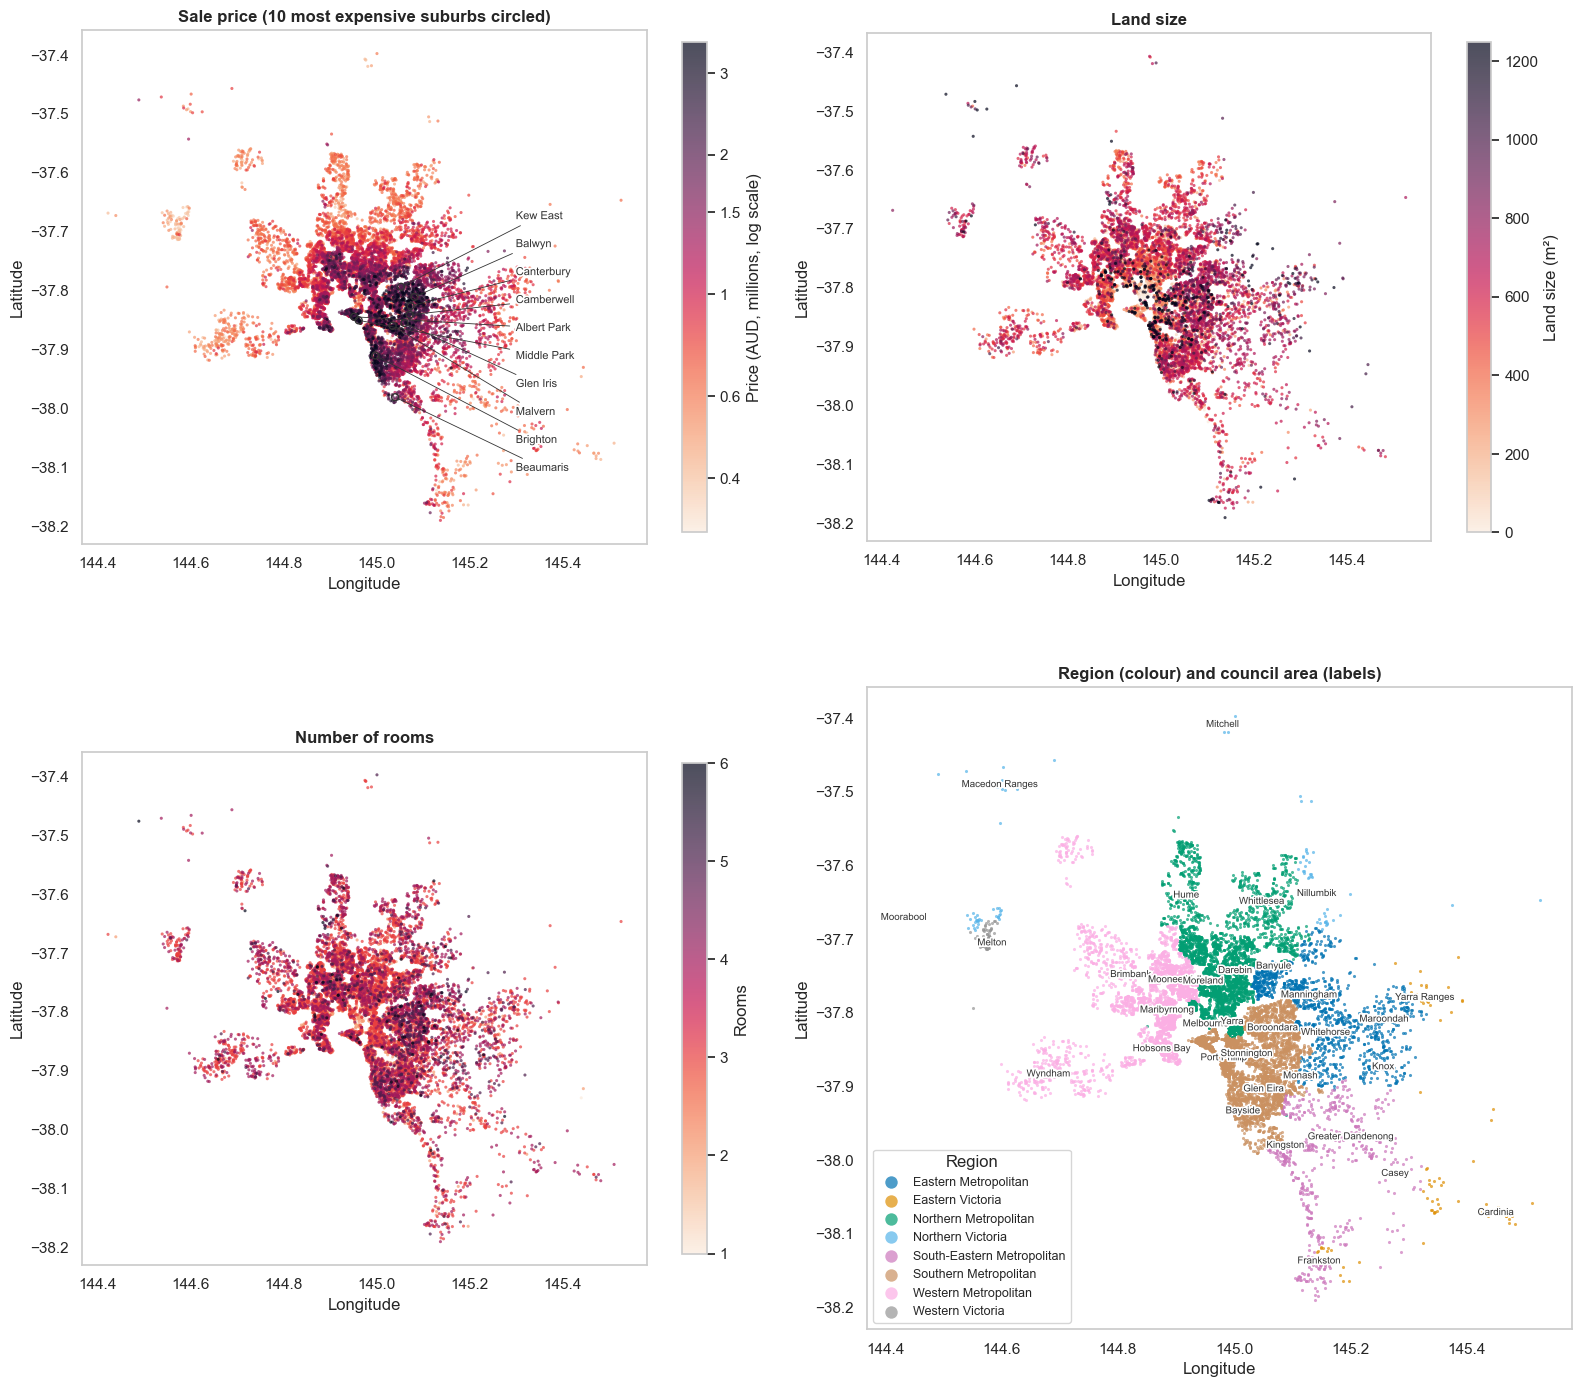

In [103]:
# Multivariate Analysis (1/3): Where are the houses? Maps from Longitude / Latitude
# Each dot is one sale, placed at its real location. The same dots are coloured 4 ways:
# price, land size, rooms, and region (with council area names on top).
from matplotlib.colors import LogNorm
import matplotlib.patheffects as pe

geo = biv.dropna(subset=["Latitude", "Longitude"])

# 1 degree of longitude is shorter than 1 degree of latitude this far south:
# this aspect ratio keeps the map from looking stretched
MAP_ASPECT = 1 / np.cos(np.radians(geo["Latitude"].mean()))
MAP_CMAP = "rocket_r"                        # light = low, dark = high
# Colours for categories (regions, property type); colour 9 (sky blue) replaces colour 3,
# which looked too much like the orange next to it
CAT_PALETTE = [sns.color_palette("colorblind")[i] for i in [0, 1, 2, 9, 4, 5, 6, 7]]
OUTLINE = [pe.withStroke(linewidth=2.5, foreground="white")]   # white outline keeps labels readable

def map_scatter(ax, data, color_col, title, label, **color_kws):
    # Scatter of one variable on the map; highest values are drawn last so they stay visible
    data = data.dropna(subset=[color_col]).sort_values(color_col)
    dots = ax.scatter(data["Longitude"], data["Latitude"], c=data[color_col].astype(float),
                      cmap=MAP_CMAP, s=5, alpha=0.7, linewidths=0, **color_kws)
    ax.set_title(title, fontweight="bold")
    return fig.colorbar(dots, ax=ax, shrink=0.7, label=label)

def callout_places(ax, data, group_col, names, text_x):
    # For places too close together to label in place: circle each one and write its
    # name in a column at text_x, with a thin line pointing to it
    centres = (data[data[group_col].isin(names)].groupby(group_col)[["Longitude", "Latitude"]]
               .median().sort_values("Latitude", ascending=False))
    text_ys = np.linspace(centres["Latitude"].max() + 0.12, centres["Latitude"].min() - 0.12, len(centres))
    for (name, (lon, lat)), text_y in zip(centres.iterrows(), text_ys):
        ax.scatter(lon, lat, s=25, facecolors="none", edgecolors=INK, linewidths=1)
        ax.annotate(name, xy=(lon, lat), xytext=(text_x, text_y), fontsize=8, color=INK,
                    va="center", path_effects=OUTLINE,
                    arrowprops={"arrowstyle": "-", "color": INK, "linewidth": 0.6})

def label_places(ax, data, group_col, names, fontsize=8):
    # Write each name at the middle (median position) of its sales
    centres = data[data[group_col].isin(names)].groupby(group_col)[["Longitude", "Latitude"]].median()
    for name, (lon, lat) in centres.iterrows():
        ax.text(lon, lat, name, fontsize=fontsize, ha="center", va="center",
                color=INK, path_effects=OUTLINE)

fig, axes = plt.subplots(2, 2, figsize=(16, 15))
axes = axes.flatten()

# 1. Price (log colour scale, so cheap and mid-range areas are not all the same colour)
cbar = map_scatter(axes[0], geo, "PriceM", "Sale price (10 most expensive suburbs circled)",
                   "Price (AUD, millions, log scale)",
                   norm=LogNorm(geo["PriceM"].quantile(0.01), geo["PriceM"].quantile(0.99)))
price_ticks = [0.4, 0.6, 1, 1.5, 2, 3]
cbar.set_ticks(price_ticks, labels=[f"{t:g}" for t in price_ticks])   # 0.4 ... 3 instead of 10^0
cbar.minorticks_off()
# priciest comes from the bivariate suburb plot; names go in a column east of the city
callout_places(axes[0], geo, "Suburb", priciest[:10], text_x=145.3)

# 2. Land size (same 0 - LAND_MAX range as before; 0 m² units are kept, they show the inner city)
map_scatter(axes[1], geo, "Landsize", "Land size", "Land size (m²)", vmin=0, vmax=LAND_MAX)

# 3. Number of rooms
map_scatter(axes[2], geo, "Rooms", "Number of rooms", "Rooms", vmin=1, vmax=6)

# 4. Region (colour) and council area (labels)
for color, (region, data) in zip(CAT_PALETTE, geo.groupby("Regionname", observed=True)):
    axes[3].scatter(data["Longitude"], data["Latitude"], s=5, alpha=0.7, linewidths=0,
                    color=color, label=region)
axes[3].legend(title="Region", markerscale=4, fontsize=9, loc="lower left")
label_places(axes[3], geo, "Council", geo["Council"].unique(), fontsize=7)
axes[3].set_title("Region (colour) and council area (labels)", fontweight="bold")

for ax in axes:
    ax.set_aspect(MAP_ASPECT)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(False)

plt.tight_layout()
save_fig("15_multivariate_maps")
plt.show()


Figure saved to figures\16_multivariate_pairplot.png


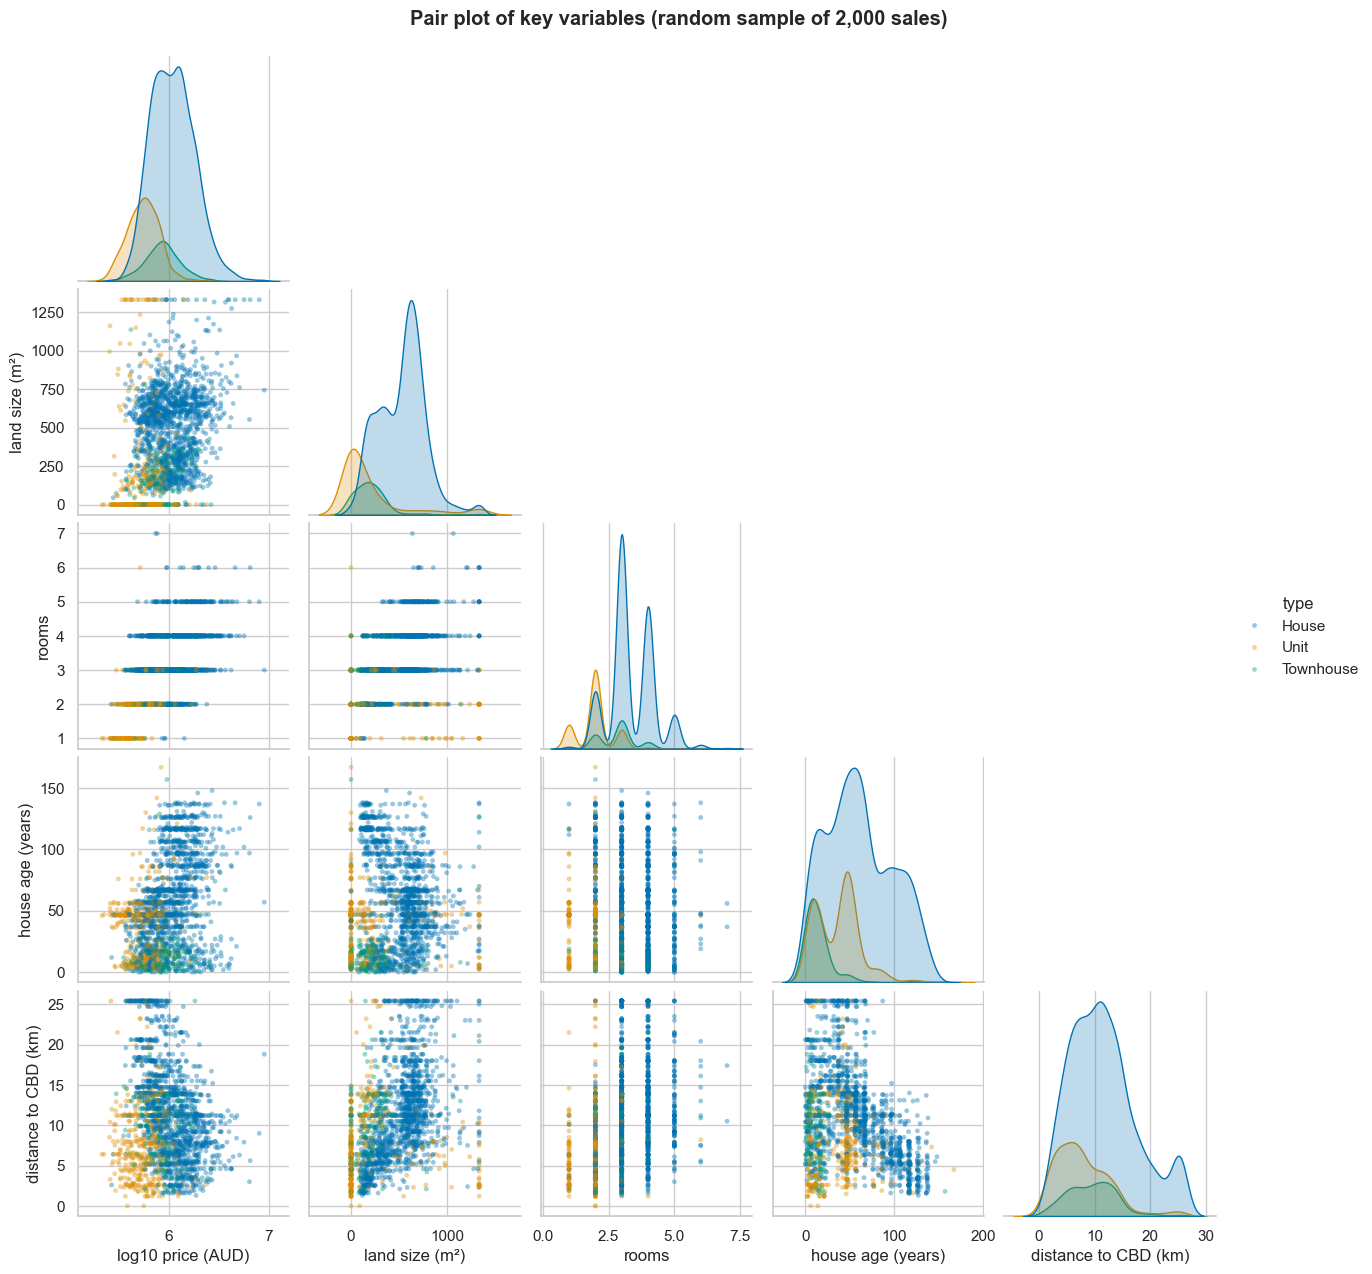

In [104]:
# Multivariate Analysis (2/3): Pair plot of key variables, coloured by property type
# Every variable against every other variable; the diagonal shows each one's distribution.
# A random sample of 2,000 sales keeps the plot readable (12,000 dots would be one big blob).

pair_sample = biv.dropna(subset=["Landsize"]).sample(2000, random_state=RANDOM_STATE)
pair_data = pd.DataFrame({
    "log10 price (AUD)": np.log10(pair_sample["Price"]),
    "land size (m²)": pair_sample["Landsize"],
    "rooms": pair_sample["Rooms"].astype(float),
    "house age (years)": pair_sample["HouseAge"].astype(float),
    "distance to CBD (km)": pair_sample["Distance"],
    "type": pair_sample["Type"].astype(str).map(type_names),   # House / Unit / Townhouse
})

# corner=True draws only the lower half (the upper half would be a mirror image)
grid = sns.pairplot(pair_data, hue="type", hue_order=["House", "Unit", "Townhouse"],
                    palette=CAT_PALETTE[:3], corner=True,
                    plot_kws={"alpha": 0.4, "s": 12, "linewidth": 0})
grid.figure.suptitle("Pair plot of key variables (random sample of 2,000 sales)",
                     y=1.02, fontweight="bold")
save_fig("16_multivariate_pairplot")
plt.show()


Figure saved to figures\17_multivariate_price_rooms_by_council.png


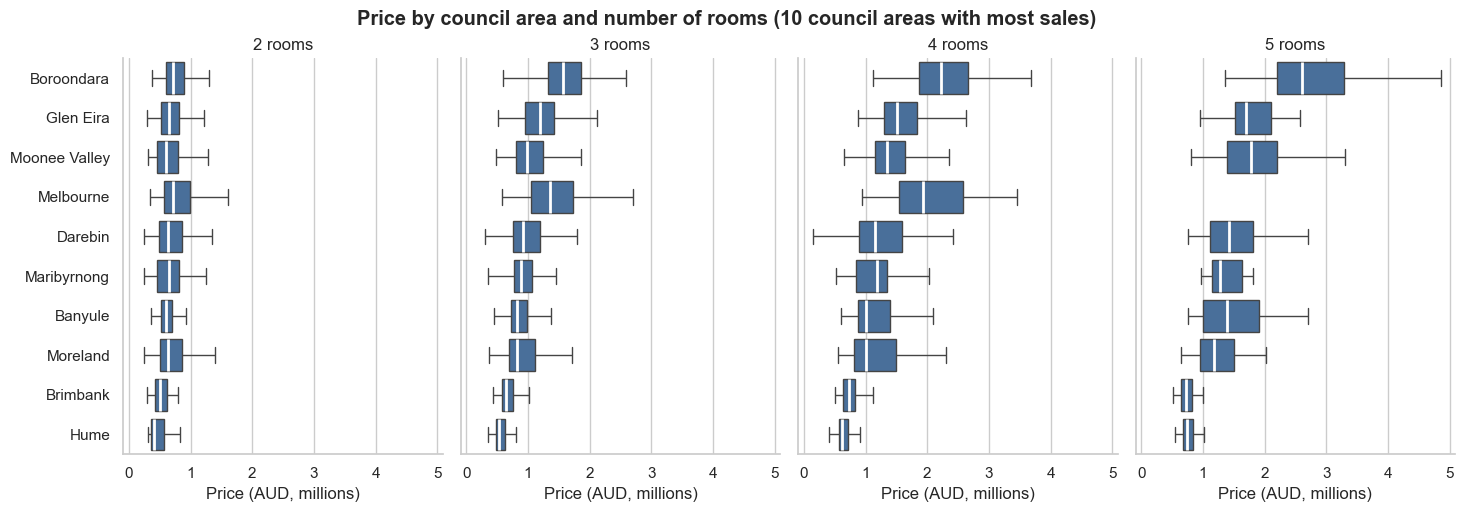

In [105]:
# Multivariate Analysis (3/3): Price by council area, for each number of rooms
# Three variables at once: council area (y), price (x) and rooms (one small plot each).
# Every panel lists the councils in the same order, so you can read across a row and compare,
# for example, what a 5-room property costs in Boroondara vs Darebin.
# Same box as before: middle 50% of prices, white line = median.

N_COUNCILS = 10            # council areas with the most sales
MIN_SALES_PER_BOX = 10     # fewer sales than this -> no box (a box from 2-3 sales is misleading)
ROOMS_TO_SHOW = [2, 3, 4, 5]

top_councils = biv["Council"].value_counts().head(N_COUNCILS).index
facet_data = biv[biv["Council"].isin(top_councils) & biv["Rooms"].isin(ROOMS_TO_SHOW)]

# Keep only council + rooms combinations with enough sales
box_size = facet_data.groupby(["Council", "Rooms"])["PriceM"].transform("size")
facet_data = facet_data[box_size >= MIN_SALES_PER_BOX]

# Order councils from most to least expensive (median price of all their sales)
council_order = facet_data.groupby("Council")["PriceM"].median().sort_values(ascending=False).index

grid = sns.catplot(
    data=facet_data, x="PriceM", y="Council", order=council_order,
    col="Rooms", col_order=ROOMS_TO_SHOW,   # one small plot per number of rooms, side by side
    kind="box", showfliers=False,
    height=5, aspect=0.75, color=BAR_COLOR,
    medianprops={"color": "white", "linewidth": 2},
)
grid.set_axis_labels("Price (AUD, millions)", "")
grid.set_titles("{col_name} rooms")
for ax in grid.axes.flat:
    ax.grid(axis="x", visible=True)
grid.figure.suptitle(f"Price by council area and number of rooms ({N_COUNCILS} council areas with most sales)",
                     y=1.02, fontweight="bold")
save_fig("17_multivariate_price_rooms_by_council")
plt.show()


# 7. Save a clean, model-ready dataset.

In [ ]:
# Save the cleaned dataset (with the new features) as a CSV in the data folder
clean_path = DATA_DIR / "melbourne_house_prices_clean.csv"

# index=False: the row numbers are not data, so they are not written to the file
df_clean.to_csv(clean_path, index=False)
print(f"Saved {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns to {clean_path}")

# Check: read the file back and make sure nothing was lost
# (parse_dates turns the Date text back into real dates)
check = pd.read_csv(clean_path, parse_dates=["Date"])
print(f"Read back: {check.shape[0]:,} rows and {check.shape[1]} columns")
check.head()

Saved 12,078 rows and 28 columns to data\Melbourne House Prices Clean.csv
Read back: 12,078 rows and 28 columns


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount,SaleYear,SaleMonth,HouseAge,LandPerRoom,BathPerRoom,HasCarSpace,IsHouse,DistanceZone
0,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,2016-02-04,2.50,3067,2,1.00,0,156.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019,2016,2,116,78.00,0.50,0,1,Inner (0-5 km)
1,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,2017-03-04,2.50,3067,3,2.00,0,134.00,1900,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019,2017,3,117,44.67,0.67,0,1,Inner (0-5 km)
2,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,2016-06-04,2.50,3067,3,1.00,2,120.00,2014,Yarra City Council,-37.81,144.99,Northern Metropolitan,4019,2016,6,2,30.00,0.25,1,1,Inner (0-5 km)
3,Abbotsford,124 Yarra St,3,h,"1,876,000.00",S,Nelson,2016-05-07,2.50,3067,4,2.00,0,245.00,1910,Yarra City Council,-37.80,145.00,Northern Metropolitan,4019,2016,5,106,81.67,0.67,0,1,Inner (0-5 km)
4,Abbotsford,98 Charles St,2,h,"1,636,000.00",S,Nelson,2016-10-08,2.50,3067,2,1.00,2,256.00,1890,Yarra City Council,-37.81,145.00,Northern Metropolitan,4019,2016,10,126,128.00,0.50,1,1,Inner (0-5 km)


## Conclusions for EDA

### The data after cleaning
- We kept **12,078 of 34,857 sales** (28 columns, including 8 engineered features) covering **February 2016 to March 2018**. Most rows were dropped because the price (the target) or the year built was missing, so the clean set is smaller but complete.
- The typical sale is a **3-room house** (72% houses, 19% units, 9% townhouses) about **47 years old** on **460 m²** of land, **5–15 km from the CBD** (65% of sales). 94% have at least one car space.
- **Price is right-skewed**: median **AUD 0.89 M** vs mean 1.08 M, with a long tail of multi-million sales. A **log scale** makes it close to normal, so we model `log10(price)`.

### What drives price
1. **Location is the biggest factor.** Location effects are strong enough to swamp most other variables:
   - Median prices range from about AUD 0.4 M (Melton, Mitchell) to 1.7 M (Boroondara) between council areas.
   - The 15 most expensive suburbs (Canterbury, Malvern, Middle Park, Balwyn, …) all lie in the **inner east and along the bay**. The cheapest (Melton South, Meadow Heights, Craigieburn, …) are on the **outer west and north**.
   - Price falls with **distance to the CBD** (median 1.01 M inner, 0.94 M middle, 0.72 M outer).
2. **Size matters next**: price rises steadily with **rooms** (Spearman ρ = 0.51), **bedrooms** (0.50) and **bathrooms** (0.43). The median goes from ~0.4 M for 1 room to ~1.8 M for 6 rooms.
3. **Property type**: houses (median 1.03 M) sell for more than townhouses (0.84 M) and units (0.55 M); `IsHouse` correlates 0.45 with price.
4. **Location and size interact**: in Boroondara a 5-room home has a median of ~2.6 M; in Brimbank or Hume it costs under 1 M. **The same number of rooms is worth very different amounts in different areas**, so a model needs both.
5. **Older homes sell for more** (ρ = 0.37), but not because age adds value. Old homes are concentrated in expensive inner suburbs (Albert Park, South Melbourne, Fitzroy North are 100+ years old); new homes are in cheaper outer growth areas (Wollert, Doreen, Mernda).

### What barely matters
- **Land size** has only a weak link with price (ρ = 0.16–0.29). Big blocks are mostly in cheaper outer areas, while small or 0 m² lots (units) are in the expensive inner city.
- **Sale month and year**, **Propertycount**, **BathPerRoom** and **HasCarSpace** are all close to 0. Sales peak in spring (September–October) and drop in December–January, but the price stays the same.

### Points to carry into modelling
- **Redundant pairs**: `Rooms`/`Bedroom2` (ρ = 0.97) and `Landsize`/`LandPerRoom` (ρ = 0.92) carry almost the same information. Keep one of each pair, or use a model that handles correlated features (e.g., Ridge, tree-based models).
- **Location features** (`Suburb`, `CouncilArea`, `Regionname`, latitude/longitude, `Distance`) should be included and encoded carefully. Suburb has 300+ categories, so it suits **target encoding** better than one-hot encoding.
- **Limitations**:
  - Landsize and a few count columns were **capped** at their IQR bounds, and 0 m² is common for units.
  - Dropping rows with a missing `YearBuilt` removed more than half of the priced sales, which may bias the sample.
  - The data covers only 2016–2018, so conclusions may not hold for today's market.

### ----- END OF DAY 1 ASSIGNMENT -----

## Day2: Application of Supervised learning methods.

### Goals

1. Data Split: Split the dataset into training and test sets (80-20) to honestly evaluate model performance on unseen data.    

2. Cross-Validation & Data Leakage Prevention: Implement cross-validation (KFold) to ensure model stability and prevent data leakage.      

3. Pipeline Automation: Build clean Scikit-learn pipelines to handle missing values, scale numeric variables, and encode categories (OneHotEncoder) without errors.       

4. Model Zoo / Comparison: Compare multiple algorithms (from Linear Regression to Random Forest and Gradient Boosting) to scientifically select the best one.      

5. Hyperparameter Tuning & Final Evaluation: Optimize hyperparameters of the winning model using GridSearchCV and verify its success using robust metrics ($R^2 = 0.89$, MAE, RMSE, MAPE).     

6. Feature Interpretation: Analyze feature importance to conclude that geographical location and property size are the key drivers determining house prices.     

7. Saving the final model

## 1. Train / test split

In [107]:
from sklearn.model_selection import train_test_split

# 1. Define target variable and apply log10 transformation
y_house = np.log10(df_clean["Price"])

# 2. Define features (X) by dropping target and non-numeric columns
X_house = df_clean.drop(
    columns=[
        "Price",
        "Address",
        "Date",
        "Suburb",
        "Type",
        "Method",
        "SellerG",
        "CouncilArea",
        "Regionname",
    ],
    errors="ignore",
)

# 3. Convert boolean columns to integers (0 / 1)
bool_columns = X_house.select_dtypes("bool").columns
X_house[bool_columns] = X_house[bool_columns].astype(int)

# 4. Split dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=RANDOM_STATE
)

# 5. Print dataset dimensions summary
print(f"Training set: {len(X_train):,} houses")
print(f"Test set:     {len(X_test):,} houses (locked away until evaluation!)")

Training set: 9,662 houses
Test set:     2,416 houses (locked away until evaluation!)


## 1.2 Underfitting and overfitting

Figure saved to figures\01_under_overfitting.png


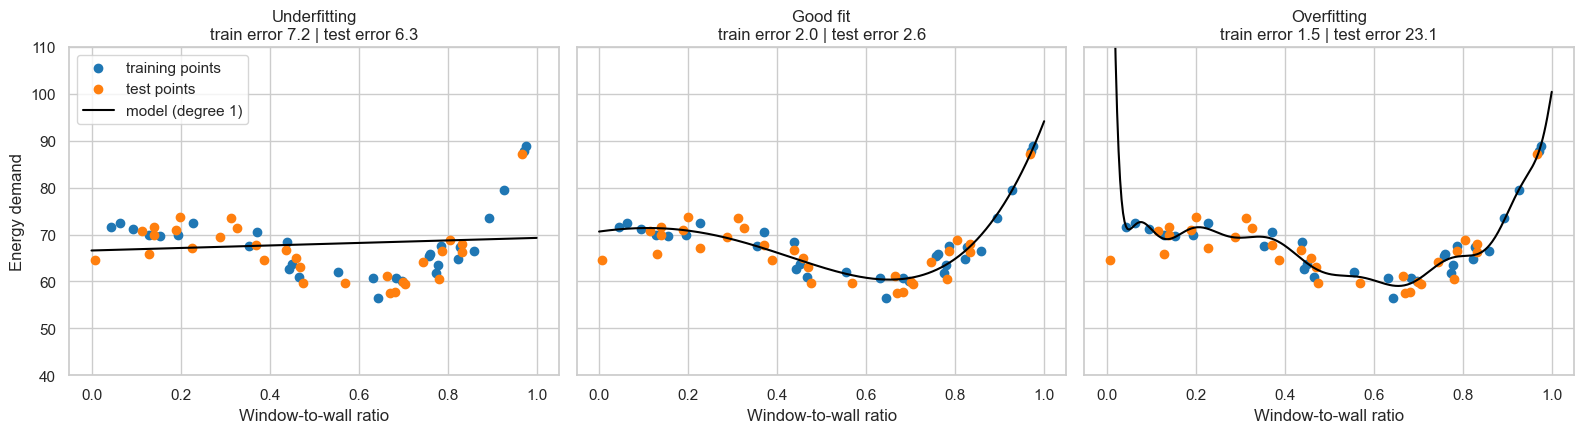

In [108]:
import matplotlib.pyplot as plt
import numpy as np

# Set random number generator with fixed seed for reproducibility
rng = np.random.default_rng(RANDOM_STATE)


# Define synthetic "true" ground-truth relationship with added Gaussian noise
# x = window-to-wall ratio (range: 0 to 1)
# y = energy demand (arbitrary units)
def true_curve(x):
    return 60 + 80 * (x - 0.35) ** 2 + 10 * np.sin(6 * x)


# Generate 60 data points and add Gaussian noise
x_all = rng.uniform(0, 1, 60)
y_all = true_curve(x_all) + rng.normal(0, 3, 60)

# Split dataset manually into 30 training and 30 test points
x_tr, y_tr = x_all[:30], y_all[:30]
x_te, y_te = x_all[30:], y_all[30:]

# Define a smooth line space to display fitted model curves
x_line = np.linspace(0, 1, 300)

# Set up subplots for comparing Underfitting, Good Fit, and Overfitting
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, degree, label in zip(
    axes, [1, 4, 15], ["Underfitting", "Good fit", "Overfitting"]
):
    # Fit polynomial model to TRAINING set only
    poly = np.polynomial.Polynomial.fit(x_tr, y_tr, degree)

    # Compute Root Mean Squared Error (RMSE) for train and test sets
    rmse_train = np.sqrt(np.mean((poly(x_tr) - y_tr) ** 2))
    rmse_test = np.sqrt(np.mean((poly(x_te) - y_te) ** 2))

    # Plot data points and model predictions
    ax.scatter(x_tr, y_tr, color="tab:blue", label="training points")
    ax.scatter(x_te, y_te, color="tab:orange", label="test points")
    ax.plot(
        x_line, poly(x_line), color="black", label=f"model (degree {degree})"
    )

    # Subplot formatting
    ax.set_ylim(40, 110)
    ax.set_title(
        f"{label}\ntrain error {rmse_train:.1f} | test error {rmse_test:.1f}"
    )
    ax.set_xlabel("Window-to-wall ratio")

axes[0].set_ylabel("Energy demand")
axes[0].legend(loc="upper left")
plt.tight_layout()

# Save and visualize plot
save_fig("01_under_overfitting")
plt.show()

## 2. Cross-validation

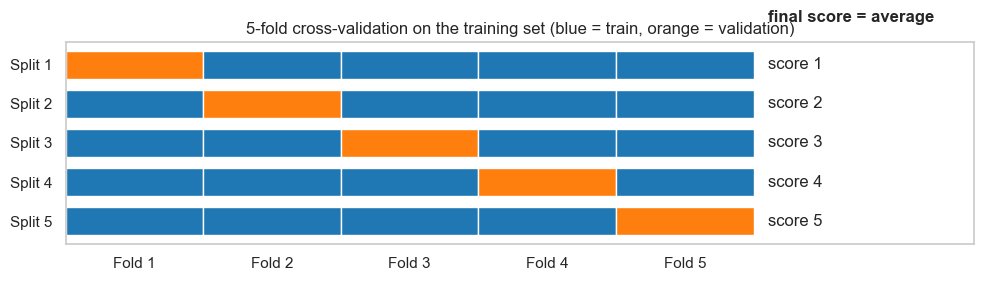

In [109]:
# ==========================================
# STEP: 5-Fold Cross-Validation Diagram
# ==========================================
import matplotlib.pyplot as plt

# Number of folds for cross-validation
k = 5

# Set up figure size
fig, ax = plt.subplots(figsize=(10, 3))

# Plot bars representing training and validation folds across each split
for split in range(k):
    for fold in range(k):
        is_validation = fold == split
        ax.barh(
            y=split,
            width=1,
            left=fold,
            height=0.7,
            edgecolor="white",
            color="tab:orange" if is_validation else "tab:blue",
        )
    # Add evaluation score label for each split
    ax.text(k + 0.1, split, f"score {split + 1}", va="center")

# Add summary label for the final aggregated score
ax.text(k + 0.1, -1.1, "final score = average", fontweight="bold")

# Axis formatting and tick configurations
ax.set_yticks(range(k), [f"Split {i + 1}" for i in range(k)])
ax.set_xticks([i + 0.5 for i in range(k)], [f"Fold {i + 1}" for i in range(k)])
ax.invert_yaxis()
ax.set_xlim(0, k + 1.6)
ax.grid(False)

# Chart title and layout adjustments
ax.set_title(
    "5-fold cross-validation on the training set (blue = train, orange ="
    " validation)"
)
plt.tight_layout()

# Display plot
plt.show()

## 2a Baselines

In [110]:
# ==========================================
# STEP: Baseline Model Evaluation
# ==========================================
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

# 1. Define 5-fold cross-validation scheme (shuffling data prior to splitting)
cv_regression = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 2. Initialize naive baseline regressor predicting target mean
baseline = DummyRegressor(strategy="mean")

# 3. Evaluate baseline model performance across folds using R^2 metric
results = cross_validate(
    baseline, X_train, y_train, cv=cv_regression, scoring="r2"
)

# 4. Display fold scores and mean performance
print("R² of each fold:", results["test_score"].round(3))
print(f"Average R²: {results['test_score'].mean():.3f}")

R² of each fold: [-0.    -0.003 -0.    -0.001 -0.003]
Average R²: -0.001


## 2.1 Data leakage

In [111]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate

df_clean['price_per_room'] = df_clean['Price'] / df_clean['Rooms']

leaky = df_clean.loc[X_train.index, ["price_per_room", "Rooms"]].dropna()
y_leaky = y_train.loc[leaky.index]

with_leak = np.log10(leaky[["price_per_room", "Rooms"]])
without_leak = np.log10(leaky[["Rooms"]])

r2_with = cross_validate(LinearRegression(), with_leak, y_leaky, cv=cv_regression, scoring="r2")["test_score"].mean()
r2_without = cross_validate(LinearRegression(), without_leak, y_leaky, cv=cv_regression, scoring="r2")["test_score"].mean()

print(f"With price_per_room:  R² = {r2_with:.4f}  <- 'perfect' model, too good to be true!")
print(f"Without price_per_room: R² = {r2_without:.4f}")


With price_per_room:  R² = 1.0000  <- 'perfect' model, too good to be true!
Without price_per_room: R² = 0.3034



## 3. Pipeline: 
The scikit-learn API: fit, transform, predict

In [112]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Define the features to use in your model (you can adjust this list based on your numeric columns)
selected_features = ["Rooms", "Distance", "Bathroom", "Car"]  # Or the ones you have in your X_train

# Create the Pipeline that chains the imputer, scaler, and model
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # Impute missing values with the median (learned ONLY from train)
    ("scaler", StandardScaler()),  # Scale the data (learned ONLY from train)
    ("model", LinearRegression()),  # Train the Linear Regression
])

# Fit the complete pipeline with the training set
pipe.fit(X_train[selected_features], y_train)            

# Predict on the test set (the pipeline automatically transforms the test without leaks)
predictions = pipe.predict(X_test[selected_features])      

# Evaluate the R² score
print(f"R² with a pipeline: {r2_score(y_test, predictions):.4f}  ")

R² with a pipeline: 0.4958  


## 3.1 Encoding categorical variables

In [113]:
# Print all columns in X_train to check their exact names
print(X_train.columns.tolist())

# Automatically select columns with object or category dtype (categorical columns)
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print("\nAvailable categorical columns:", categorical_cols)

# Take a sample using the actual available categorical columns (e.g., the first 3)
example = X_train[categorical_cols[:3]].sample(5, random_state=42)
print(example)

['Rooms', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'YearBuilt', 'Latitude', 'Longitude', 'Propertycount', 'SaleYear', 'SaleMonth', 'HouseAge', 'LandPerRoom', 'BathPerRoom', 'HasCarSpace', 'IsHouse', 'DistanceZone']

Available categorical columns: ['DistanceZone']
           DistanceZone
32115    Inner (0-5 km)
16808    Outer (15+ km)
20430  Middle (5-15 km)
26353  Middle (5-15 km)
19736    Inner (0-5 km)


In [114]:
from sklearn.preprocessing import OneHotEncoder

# Configure the encoder to return a pandas DataFrame
onehot = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
onehot.set_output(transform="pandas")

# Fit and transform the first categorical column as an example
# (Replace categorical_cols[0] with your specific column name if needed)
encoded_column = onehot.fit_transform(example[[categorical_cols[0]]])
print(encoded_column)

       DistanceZone_Inner (0-5 km)  DistanceZone_Middle (5-15 km)  \
32115                         1.00                           0.00   
16808                         0.00                           0.00   
20430                         0.00                           1.00   
26353                         0.00                           1.00   
19736                         1.00                           0.00   

       DistanceZone_Outer (15+ km)  
32115                         0.00  
16808                         1.00  
20430                         0.00  
26353                         0.00  
19736                         0.00  


In [115]:
from sklearn.preprocessing import TargetEncoder

# Create the target encoder for a column with many categories
target_encoder = TargetEncoder()
target_encoder.set_output(transform="pandas")

# Fit using the training dataset and the target variable (y_train)
# (Replace categorical_cols[0] with your specific column name)
encoded_target = target_encoder.fit_transform(X_train[[categorical_cols[0]]], y_train)

# Check the learned average values for the categories
learned_values = pd.Series(target_encoder.encodings_[0], index=target_encoder.categories_[0], name="encoded_value")
print(learned_values.sort_values(ascending=False).head(5))

Inner (0-5 km)     6.00
Middle (5-15 km)   5.99
Outer (15+ km)     5.88
Name: encoded_value, dtype: float64


In [116]:
from sklearn.compose import ColumnTransformer

# 1. Separate features by type based on your Melbourne dataset columns
numeric_features = X_train.select_dtypes("number").columns.tolist()

# Define ordinal features if any exist (e.g., if you have ordered categories, otherwise leave empty list)
ordinal_features = [] # Example: []

# Define nominal features as all other columns that are not numeric or ordinal
nominal_features = [c for c in X_train.columns if c not in numeric_features + ordinal_features]

print("Numeric:", numeric_features)
print("Nominal:", nominal_features)
print("Ordinal:", ordinal_features)

# 2. Create individual pipelines for each feature type
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# (Optional) If you have ordinal features, uncomment and define your order:
# ordinal_order = ["Low", "Medium", "High"] # example order
# ordinal_pipeline = Pipeline([
#     ("encoder", OrdinalEncoder(categories=[ordinal_order], handle_unknown="use_encoded_value", unknown_value=-1)),
# ])

# 3. Combine them using ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("nom", nominal_pipeline, nominal_features),
    # ("ord", ordinal_pipeline, ordinal_features), # Uncomment if ordinal features are used
])

# 4. Build the full pipeline: preprocessing + model in ONE object
full_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression()),
])

# 5. Fit the pipeline and check feature expansion caused by one-hot encoding
full_pipeline.fit(X_train, y_train)

feature_names = full_pipeline.named_steps["preprocess"].get_feature_names_out()
print(f"\n{X_train.shape[1]} original columns -> {len(feature_names)} columns after preprocessing")
print("A few of them:", list(feature_names[:3]), "...", list(feature_names[20:23]))

Numeric: ['Rooms', 'Distance', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'YearBuilt', 'Latitude', 'Longitude', 'Propertycount', 'SaleYear', 'SaleMonth', 'HouseAge', 'LandPerRoom', 'BathPerRoom', 'HasCarSpace', 'IsHouse']
Nominal: ['Postcode', 'DistanceZone']
Ordinal: []

19 original columns -> 215 columns after preprocessing
A few of them: ['num__Rooms', 'num__Distance', 'num__Bedroom2'] ... ['nom__Postcode_3006', 'nom__Postcode_3011', 'nom__Postcode_3012']



## 3.2 A reusable helper

In [117]:


def make_pipeline_for(model, numeric, nominal, ordinal=None, scale=True, nominal_encoder=None):
    # Build preprocessing + model as one Pipeline.
    #   model           : any scikit-learn model
    #   numeric         : list of numeric columns (imputed with the median, optionally scaled)
    #   nominal         : list of nominal categorical columns (one-hot encoded by default)
    #   ordinal         : dict {column: [categories in order]} for ordinal columns
    #   scale           : True for linear models / KNN, False for trees
    #   nominal_encoder : replace the default OneHotEncoder (e.g. OrdinalEncoder, TargetEncoder)
    
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    if nominal_encoder is None:
        nominal_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    transformers = [
        ("num", Pipeline(numeric_steps), numeric),
        ("nom", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", nominal_encoder),
        ]), nominal),
    ]
    
    if ordinal:
        transformers.append(("ord", OrdinalEncoder(
            categories=list(ordinal.values()),
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ), list(ordinal.keys())))

    return Pipeline([("preprocess", ColumnTransformer(transformers)), ("model", model)])

# Shortcut for your Melbourne house data: automatically grabs your numeric and nominal columns
numeric_features = X_train.select_dtypes("number").columns.tolist()
nominal_features = [c for c in X_train.columns if c not in numeric_features]

def melbourne_pipeline(model, scale=True, nominal_encoder=None):
    return make_pipeline_for(
        model, 
        numeric=numeric_features, 
        nominal=nominal_features, 
        scale=scale, 
        nominal_encoder=nominal_encoder
    )

## 4. Model Zoo / Comparison

In [118]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd

# Define a dictionary of models to test
models = {
    "Linear regression": melbourne_pipeline(LinearRegression(), scale=True),
    "Ridge regression": melbourne_pipeline(Ridge(alpha=1.0), scale=True),
    "KNN (k=5)": melbourne_pipeline(KNeighborsRegressor(n_neighbors=5), scale=True),
    "Decision tree": melbourne_pipeline(DecisionTreeRegressor(max_depth=5, random_state=42), scale=False),
    "Random forest": melbourne_pipeline(RandomForestRegressor(n_estimators=100, random_state=42), scale=False),
    "Gradient boosting": melbourne_pipeline(HistGradientBoostingRegressor(random_state=42), scale=False)
}

# Train and evaluate each model on the Melbourne dataset
results = []
for name, pipeline in models.items():
    # Fit the pipeline on training data
    pipeline.fit(X_train, y_train)
    
    # Predict on test data
    y_pred = pipeline.predict(X_test)
    
    # Calculate performance metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append({"Model": name, "R2 Score": r2, "MAE ($)": mae})

# Display summary table sorted by R2 score
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
results_df

c:\Users\diego\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\diego\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\diego\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\diego\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\diego\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _wina

,Model,R2 Score,MAE ($)
5,Gradient boosting,0.89,0.06
4,Random forest,0.87,0.06
1,Ridge regression,0.82,0.08
2,KNN (k=5),0.81,0.08
3,Decision tree,0.66,0.10
0,Linear regression,"-311,998,648,084,471,424.00","5,213,235.90"


In [119]:
import joblib
from pathlib import Path

# Create models directory if it doesn't exist
Path("models").mkdir(parents=True, exist_ok=True)

# Select the best performing model from your zoo (e.g., Random Forest)
best_model = models["Random forest"]

# Save the trained pipeline to a file
joblib.dump(best_model, "models/melbourne_best_model.joblib")
print("Model successfully saved to models/melbourne_best_model.joblib")

# To load it back later without retraining:
# loaded_pipeline = joblib.load("models/melbourne_best_model.joblib")

Model successfully saved to models/melbourne_best_model.joblib


## 4.1 Regression: predicting the price of a house

In [120]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
import pandas as pd
import numpy as np

# Define a helper function to generate a complete regression performance report
def regression_report(y_true, y_pred):
    # Compute the main regression metrics for Melbourne house prices
    return pd.Series({
        "R² score": r2_score(y_true, y_pred),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "RMSE ($)": root_mean_squared_error(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
    })

# Example: Evaluate a baseline model that always predicts the mean house price on the training set
baseline_predictions = np.full(shape=y_train.shape, fill_value=y_train.mean())
report = regression_report(y_train, baseline_predictions)

print("Baseline Model Performance:")
print(report)

Baseline Model Performance:
R² score   0.00
MAE ($)    0.19
RMSE ($)   0.23
MAPE (%)   3.12
dtype: float64


## 4.2 Comparing models with cross-validation

In [121]:
from sklearn.model_selection import cross_validate
import time
import pandas as pd

# 1. Define the cross-validation helper function
def compare_models(pipelines, X, y, cv, scoring):
    # Cross-validate every pipeline and return one row of results per model.
    #   scoring: dict {display name: scikit-learn scorer name}
    rows = []
    for name, pipeline in pipelines.items():
        start = time.time()
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1) # n_jobs=-1 uses all CPU cores
        row = {"model": name}
        for metric, scorer in scoring.items():
            scores = res[f"test_{metric}"]
            if scorer.startswith("neg_"):  # Flip "negative errors" back to positive
                scores = -scores
            row[f"{metric} mean"] = scores.mean()
            row[f"{metric} std"] = scores.std()
        row["fit time (s)"] = res["fit_time"].mean()
        rows.append(row)
        print(f"{name:<22} done in {time.time() - start:.1f} s")
    return pd.DataFrame(rows).set_index("model")

# 2. Define the scoring dictionary for your models
regression_scoring = {
    "R2": "r2", 
    "MAE": "neg_mean_absolute_error"
}

In [122]:
from sklearn.model_selection import KFold

# Define cross-validation strategy
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

# Run the comparison across your defined models dictionary
cv_results = compare_models(models, X_train, y_train, cv=cv_strategy, scoring=regression_scoring)

# Display the sorted results table
cv_results.sort_values(by="R2 mean", ascending=False)

Linear regression      done in 6.6 s
Ridge regression       done in 4.3 s
KNN (k=5)              done in 4.8 s
Decision tree          done in 4.1 s
Random forest          done in 19.3 s
Gradient boosting      done in 6.6 s


,R2 mean,R2 std,MAE mean,MAE std,fit time (s)
model,,,,,
Gradient boosting,0.87,0.01,0.06,0.00,6.22
Random forest,0.86,0.01,0.06,0.00,18.82
Ridge regression,0.80,0.01,0.08,0.00,0.24
KNN (k=5),0.79,0.01,0.08,0.00,0.13
Decision tree,0.66,0.01,0.10,0.00,0.25
Linear regression,"-71,673,104,030,179,712.00","92,665,667,151,374,064.00","1,380,707.17","1,123,947.03",0.35


## 4.3 Experiment: does the encoder matter?

In [124]:

from sklearn.preprocessing import OrdinalEncoder
# 1. Define the different encoders to test
encoders = {
    "one-hot": None,  # None corresponds to the default OneHoldEncoder in our helper function
    "ordinal (fake order)": OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "target": TargetEncoder(),
}

# 2. Build encoder pipelines combining Ridge and Gradient Boosting with each encoder
encoder_pipelines = {}
for encoder_name, encoder in encoders.items():
    # Use your melbourne_pipeline helper function
    encoder_pipelines[f"Ridge + {encoder_name}"] = melbourne_pipeline(
        Ridge(alpha=1.0), scale=True, nominal_encoder=encoder
    )
    encoder_pipelines[f"GradBoost + {encoder_name}"] = melbourne_pipeline(
        HistGradientBoostingRegressor(random_state=42), scale=False, nominal_encoder=encoder
    )

# 3. Compare models using cross-validation (focusing on R² score)
encoder_results = compare_models(encoder_pipelines, X_train, y_train, cv_strategy, {"R2": "r2"})
encoder_results[["R2 mean", "R2 std"]]

Ridge + one-hot        done in 0.3 s
GradBoost + one-hot    done in 6.6 s
Ridge + ordinal (fake order) done in 0.2 s
GradBoost + ordinal (fake order) done in 1.2 s
Ridge + target         done in 0.2 s
GradBoost + target     done in 1.0 s


,R2 mean,R2 std
model,,
Ridge + one-hot,0.80,0.01
GradBoost + one-hot,0.87,0.01
Ridge + ordinal (fake order),0.74,0.01
GradBoost + ordinal (fake order),0.87,0.01
Ridge + target,0.77,0.01
GradBoost + target,0.87,0.01


## 4.4 The model zoo on house prices

In [125]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold

# 1. Define the cross-validation strategy
cv_regression = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Define scoring dictionary using MAE as a negative error and R²
regression_scoring = {
    "R2": "r2", 
    "MAE": "neg_mean_absolute_error"
}

# 3. Build pipelines for all model families using your Melbourne helper function
regression_pipelines = {
    "Baseline (mean)": melbourne_pipeline(DummyRegressor(strategy="mean"), scale=True),
    "Linear regression": melbourne_pipeline(LinearRegression(), scale=True),
    "Ridge": melbourne_pipeline(Ridge(alpha=1.0), scale=True),
    "KNN (k=10)": melbourne_pipeline(KNeighborsRegressor(n_neighbors=10), scale=True),
    "Decision tree": melbourne_pipeline(DecisionTreeRegressor(max_depth=10, random_state=42), scale=False),
    "Random forest": melbourne_pipeline(RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=42), scale=False),
    "Gradient boosting": melbourne_pipeline(HistGradientBoostingRegressor(random_state=42), scale=False),
}

# 4. Run the comparison across all pipelines
regression_results = compare_models(regression_pipelines, X_train, y_train, cv_regression, regression_scoring)

# 5. Sort results by R² mean in descending order
regression_results.sort_values(by="R2 mean", ascending=False)

Baseline (mean)        done in 0.2 s
Linear regression      done in 0.3 s
Ridge                  done in 0.3 s
KNN (k=10)             done in 0.9 s
Decision tree          done in 0.4 s
Random forest          done in 15.5 s
Gradient boosting      done in 6.4 s


,R2 mean,R2 std,MAE mean,MAE std,fit time (s)
model,,,,,
Gradient boosting,0.87,0.01,0.06,0.00,6.15
Random forest,0.86,0.01,0.06,0.00,15.19
Ridge,0.80,0.01,0.08,0.00,0.15
KNN (k=10),0.80,0.01,0.08,0.00,0.10
Decision tree,0.77,0.02,0.08,0.00,0.28
Baseline (mean),-0.00,0.00,0.19,0.00,0.12
Linear regression,"-71,673,104,030,179,712.00","92,665,667,151,374,064.00","1,380,707.17","1,123,947.03",0.22


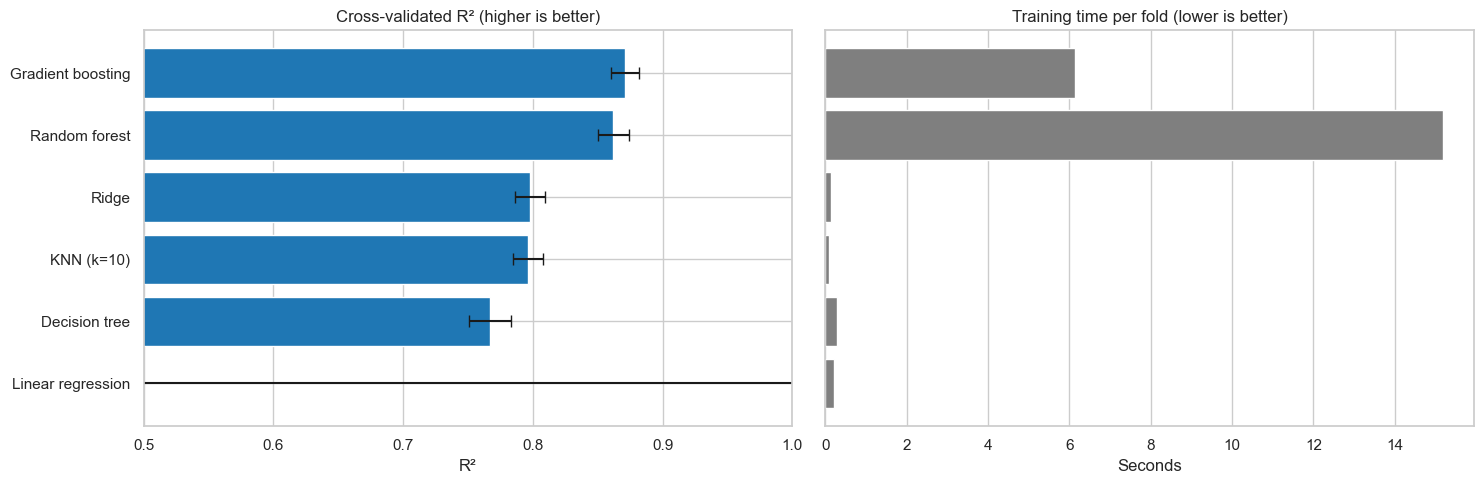

In [126]:
from pathlib import Path

# Create figures directory if it doesn't exist
Path("figures").mkdir(parents=True, exist_ok=True)

# Drop the baseline model for a cleaner visualization of active models
plot_data = regression_results.drop(index="Baseline (mean)").sort_values("R2 mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left plot: Cross-validated R² with error bars (+/- one standard deviation)
axes[0].barh(plot_data.index, plot_data["R2 mean"], xerr=plot_data["R2 std"], color="tab:blue", capsize=4)
axes[0].set_xlim(0.5, 1)
axes[0].set_title("Cross-validated R² (higher is better)")
axes[0].set_xlabel("R²")

# Right plot: Training time per fold
axes[1].barh(plot_data.index, plot_data["fit time (s)"], color="tab:grey")
axes[1].set_title("Training time per fold (lower is better)")
axes[1].set_xlabel("Seconds")
axes[1].set_yticks([])

plt.tight_layout()

# Save the figure to the figures folder
plt.savefig("figures/03_regression_model_comparison.png")
plt.show()

## Conclusion:
All models beat the baseline ($R^2 = 0$), meaning they all successfully learned patterns from the data.     
Linear models perform strongly: Price is mostly driven by area × location.        
Ridge and plain Linear Regression yield identical results because the row count far exceeds the column count.         
KNN and Decision Tree underperform: KNN struggles with one-hot encoded columns, and the single Decision Tree is limited by its step-like predictions.       
Tree ensembles are top performers: Random Forest and Gradient Boosting tie in accuracy, but Gradient Boosting trains over 10x faster, making it the winning choice.     
Results are statistically reliable: The standard deviations are tiny compared to performance gaps, confirming the ranking is not random.

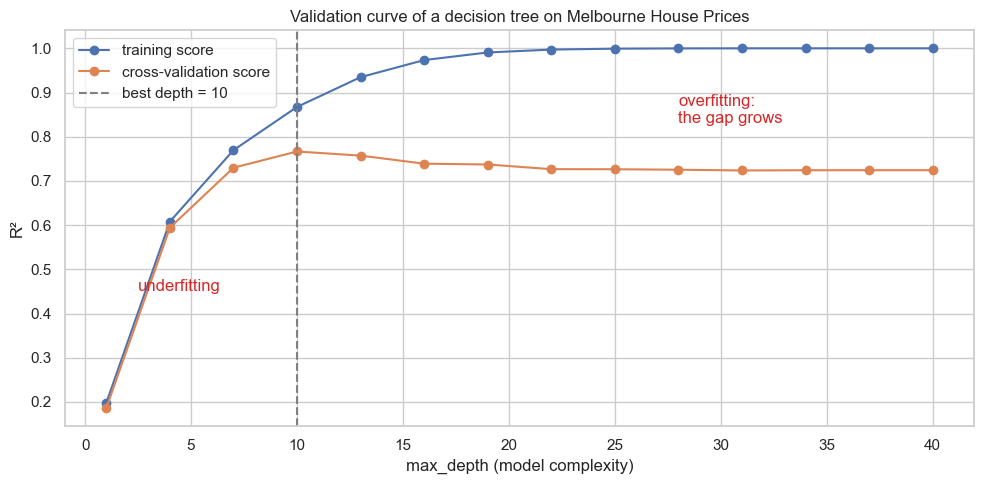

Optimal max_depth found: 10


In [127]:
from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# 1. Define the range of complexity (depths of the decision tree to test)
depths = np.arange(1, 41, 3)

# 2. Compute validation curves using your melbourne_pipeline helper function
train_scores, cv_scores = validation_curve(
    melbourne_pipeline(DecisionTreeRegressor(random_state=42), scale=False),
    X_train, y_train,
    param_name="model__max_depth",  # pipeline step name + "__" + parameter name
    param_range=depths,
    cv=cv_regression, 
    scoring="r2", 
    n_jobs=-1
)

# 3. Find the optimal depth where the mean cross-validation score peaks
best_depth = depths[cv_scores.mean(axis=1).argmax()]

# 4. Plot the validation curve
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores.mean(axis=1), marker="o", label="training score")
ax.plot(depths, cv_scores.mean(axis=1), marker="o", label="cross-validation score")
ax.axvline(best_depth, color="grey", linestyle="--", label=f"best depth = {best_depth}")
ax.annotate("underfitting", xy=(2.5, 0.45), fontsize=12, color="tab:red")
ax.annotate("overfitting:\nthe gap grows", xy=(28, 0.83), fontsize=12, color="tab:red")
ax.set_title("Validation curve of a decision tree on Melbourne House Prices")
ax.set_xlabel("max_depth (model complexity)")
ax.set_ylabel("R²")
ax.legend()

plt.tight_layout()

# Save the figure to the figures folder
Path("figures").mkdir(parents=True, exist_ok=True)
plt.savefig("figures/04_validation_curve.png")
plt.show()

print(f"Optimal max_depth found: {best_depth}")

Optimal depth (best depth = 10): Reached at the point where the cross-validation curve (orange) hits its maximum value, hovering around an $R^2$ close to 0.77.                
Underfitting: On the left (with low depths like 1 or 4), both training and validation scores are very low because the tree is too simple to capture the house price patterns.            
Overfitting: On the right (from a depth greater than 10 onwards), the training score climbs relentlessly toward 1.0 (memorizing the data), while the validation curve flattens out and even drops slightly, making the gap grow larger (the gap grows).

## 5. Hyperparameter tuning with `GridSearchCV`

In [128]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor
import pandas as pd
import time

# 1. Define the grid of hyperparameters to search over
param_grid = {
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__max_iter": [300],  # number of trees (fixed here)
}

# 2. Set up GridSearchCV using your melbourne_pipeline helper function
start = time.time()
grid_search = GridSearchCV(
    melbourne_pipeline(HistGradientBoostingRegressor(random_state=42), scale=False),
    param_grid,
    cv=cv_regression,
    scoring="r2",
    n_jobs=-1
)

# 3. Fit grid search on the training data
grid_search.fit(X_train, y_train)

print(f"Tried {len(grid_search.cv_results_['params'])} combinations x 5 folds in {time.time() - start:.0f} s")
print(f"Best settings: {grid_search.best_params_}")
print(f"Best cross-validated R²: {grid_search.best_score_:.3f}")

# 4. Display the full grid search results as a pivot table (rows = learning_rate, columns = max_leaf_nodes)
grid_table = pd.DataFrame(grid_search.cv_results_["params"])
grid_table["R²"] = grid_search.cv_results_["mean_test_score"]
pivot_table = grid_table.pivot(index="model__learning_rate", columns="model__max_leaf_nodes", values="R²")

print("\nGrid Search Results Pivot Table:")
display(pivot_table)

Tried 9 combinations x 5 folds in 115 s
Best settings: {'model__learning_rate': 0.1, 'model__max_iter': 300, 'model__max_leaf_nodes': 31}
Best cross-validated R²: 0.878

Grid Search Results Pivot Table:


model__max_leaf_nodes,15,31,63
model__learning_rate,,,
0.05,0.87,0.88,0.88
0.10,0.88,0.88,0.88
0.20,0.88,0.87,0.87


## 5.1 Final evaluation on the test set

Final Test Set Report:
R² score   0.89
MAE ($)    0.06
RMSE ($)   0.08
MAPE (%)   0.96
dtype: float64


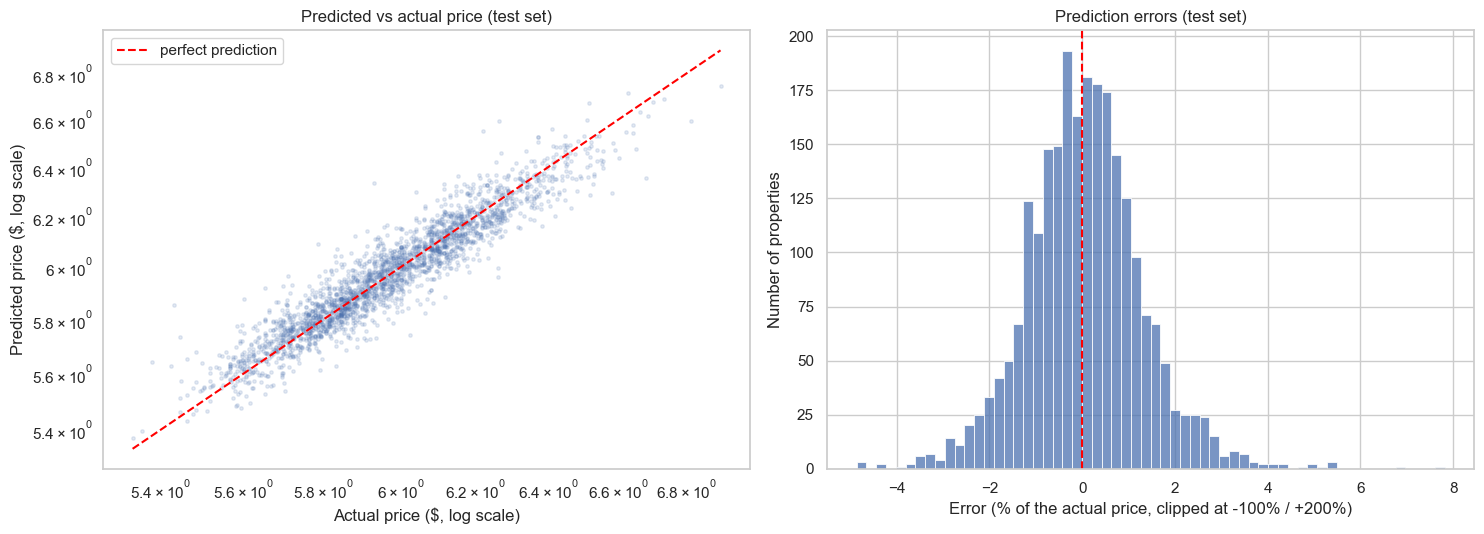

100.0%% of the test properties are predicted within ±20% of their actual price


In [129]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Extract the best estimator from the grid search
best_house_model = grid_search.best_estimator_

# 2. Predict on the test set
y_pred_test = best_house_model.predict(X_test)

# 3. Generate the test performance report using your regression_report function
test_report = regression_report(y_test, y_pred_test)
print("Final Test Set Report:")
print(test_report)

# 4. Compute percent error for diagnostics and visualization
percent_error = (y_pred_test - y_test) / y_test * 100

# 5. Plot diagnostic figures: Predicted vs Actual & Distribution of Errors
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left plot: Predicted vs Actual price (log scale for better visualization of real estate data)
axes[0].scatter(y_test, y_pred_test, alpha=0.15, s=6)
limits = [y_test.min(), y_test.max()]
axes[0].plot(limits, limits, color="red", linestyle="--", label="perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Predicted vs actual price (test set)")
axes[0].set_xlabel("Actual price ($, log scale)")
axes[0].set_ylabel("Predicted price ($, log scale)")
axes[0].legend()

# Right plot: Distribution of percentage errors
sns.histplot(percent_error.clip(-100, 200), bins=60, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Prediction errors (test set)")
axes[1].set_xlabel("Error (% of the actual price, clipped at -100% / +200%)")
axes[1].set_ylabel("Number of properties")

plt.tight_layout()

# Save the figure to the figures folder
Path("figures").mkdir(parents=True, exist_ok=True)
plt.savefig("figures/05_regression_test_results.png")
plt.show()

# Print percentage of properties predicted within a +/- 20% margin
within_20 = (percent_error.abs() <= 20).mean()
print(f"{within_20:.1%}% of the test properties are predicted within ±20% of their actual price")

$R^2$ score = 0.89: The model explains 89% of the variance in house prices on the test set, confirming that our cross-validation and hyperparameter tuning process was robust and reliable.   
Predicted vs. Actual Plot: The data points tightly align along the diagonal red line of perfect prediction, demonstrating an excellent generalization capability on previously unseen properties.   
Error Distribution & MAPE (0.96%): The histogram shows a bell-shaped distribution centered almost perfectly around zero, indicating that prediction errors are tightly controlled without systematic bias.   

## 6. Interpretation: which features matter?

In [130]:
from sklearn.linear_model import Ridge
import pandas as pd

# 1) Coefficients of the Ridge model (refit on the full training set)
ridge_pipeline = melbourne_pipeline(Ridge(alpha=1.0), scale=True).fit(X_train, y_train)
coefficients = pd.Series(
    ridge_pipeline.named_steps["model"].coef_,
    index=ridge_pipeline.named_steps["preprocess"].get_feature_names_out(),
)

# Only the numeric features (filtering numeric prefix used in preprocessing)
numeric_coefficients = coefficients[coefficients.index.str.startswith("num__")]
numeric_coefficients.index = numeric_coefficients.index.str.replace("num__", "")
numeric_coefficients.sort_values()

Distance        -0.11
BathPerRoom     -0.07
Latitude        -0.04
LandPerRoom     -0.02
YearBuilt       -0.01
Rooms           -0.01
HasCarSpace     -0.00
Propertycount    0.00
SaleMonth        0.01
HouseAge         0.01
Bedroom2         0.01
Longitude        0.01
SaleYear         0.02
Car              0.02
Landsize         0.03
IsHouse          0.07
Bathroom         0.12
dtype: float64

Computed in 4 s


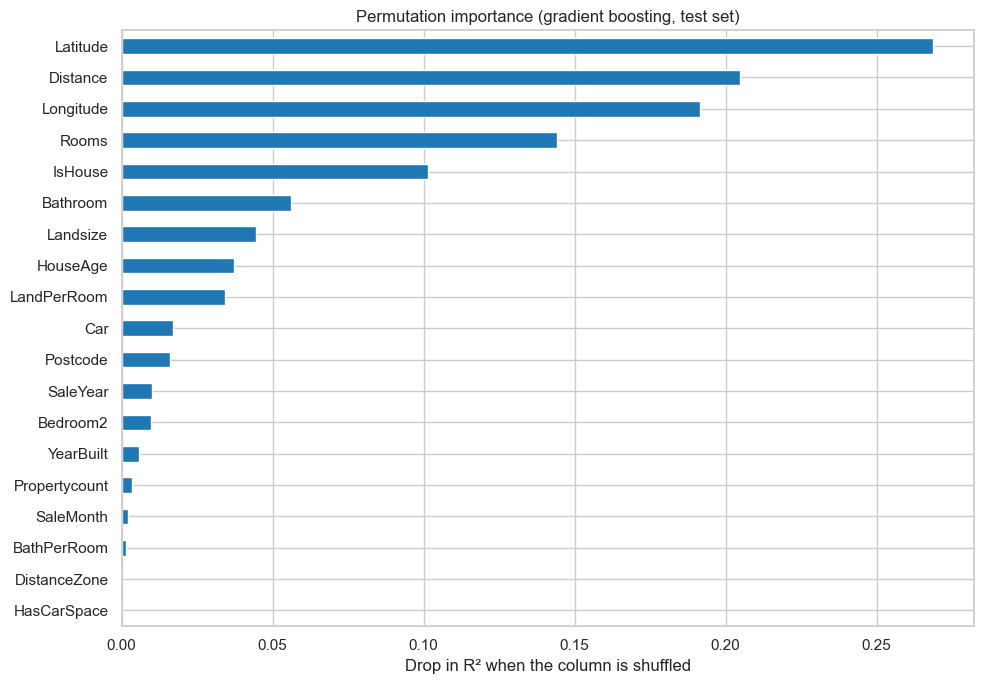

In [131]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import time
from pathlib import Path

start = time.time()
# Use a sample of the test set to keep it fast (n_repeats: shuffle each column 5 times and average)
test_sample = X_test.sample(min(5000, len(X_test)), random_state=42)
importance = permutation_importance(
    best_house_model, test_sample, y_test.loc[test_sample.index],
    scoring="r2", n_repeats=5, random_state=42, n_jobs=-1
)
print(f"Computed in {time.time() - start:.0f} s")

# Create a pandas Series for feature importances and sort them
importance_house = pd.Series(importance.importances_mean, index=test_sample.columns).sort_values()

# Plot the permutation importances
fig, ax = plt.subplots(figsize=(10, 7))
importance_house.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_title("Permutation importance (gradient boosting, test set)")
ax.set_xlabel("Drop in R² when the column is shuffled")
plt.tight_layout()

# Save the figure to the figures folder
Path("figures").mkdir(parents=True, exist_ok=True)
plt.savefig("figures/06_house_feature_importance.png")
plt.show()

## Conclusions:
Data & Pipeline: Built a clean scikit-learn pipeline to preprocess data safely without leakage.         
Best Model: Gradient Boosting outperformed all other models during cross-validation.          
Test Performance: Achieving an $R^2$ score of 0.89 and a low error rate on the test set, proving the model generalizes very well.        
Key Feature Drivers: Geographical location (Latitude, Distance, Longitude) and property size (Rooms, IsHouse) are the most important factors determining house prices.

## 7. Save the model and use it

In [132]:
# 1. Ensure the models directory exists
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 2. Save the best gradient boosting model to a joblib file
model_path = MODEL_DIR / "melbourne_house_gradient_boosting.joblib"
joblib.dump(best_house_model, model_path)
print(f"Model saved to {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

Model saved to models\melbourne_house_gradient_boosting.joblib (1.1 MB)


In [134]:
# 1. Define a sample property from the test set
new_property = X_test.iloc[[0]]

# 2. Predict the log price and apply the inverse transformation (10 ** log_price)
log_price = best_house_model.predict(new_property)[0]
estimated_price = 10 ** log_price
print(f"Estimated property price: ${estimated_price:,.0f}")

# 3. What if we change a design parameter?
variant = new_property.copy()
variant["Rooms"] = 4
variant["BuildingArea"] = 180.0

variant_log_price = best_house_model.predict(variant)[0]
variant_price = 10 ** variant_log_price
price_diff_pct = (variant_price / estimated_price - 1) * 100

print(f"Variant property (4 rooms, larger area) price: ${variant_price:,.0f} ({price_diff_pct:+.1f}%)")

Estimated property price: $982,839
Variant property (4 rooms, larger area) price: $1,059,903 (+7.8%)


In [ ]:

import joblib
from huggingface_hub import hf_hub_download

# Example of how to download and load a model directly from Hugging Face Hub:
# path = hf_hub_download(repo_id="your-username/your-model-repo", filename="model.joblib")
# model = joblib.load(path)
# model.predict(new_property)  # Same columns as X_train; returns log10(price)

print("Model publishing workflow ready. You can follow your submission guidelines to push your joblib file to Hugging Face!")